# Exploratory Data Analysis (EDA): U.S. Stock Market, Bonds, T-Bills & Inflation (1871–2026)

**Project:** Multi-Horizon Stock Market Return Forecasting, Factor Premiums, and Drawdown Dynamics  
**Team:** Raphael Erler, Richard Zallinger, Michael Prokop  
**Course:** Foundations of Data Engineering and Analytics (WS 2026)

---

### Research Goal & Role of Exploratory Data Analysis (Section 3.2)
Our overarching research question asks:
> **How well do valuation ratios (`P/E`, `CAPE`), momentum (`6M`, `12M`), volatility (`12M`), and drawdowns predict real U.S. stock returns over 1, 5, and 10 years, and can rule-based or machine-learning strategies outperform simple buy-and-hold or fixed-income benchmarks?**

Following **John W. Tukey's (1977)** EDA framework and the course taxonomy (*Lecture `DEA-04`*), we cross-classify our exploration along two dimensions:
1. **Univariate Non-Graphical & Graphical EDA** (tabulation, location, spread, skewness, kurtosis, normality, histograms, KDEs, boxplots, violin plots, Q-Q plots), focusing first on **CPI inflation** and **real equity returns**.
2. **Bivariate & Multivariate Non-Graphical & Graphical EDA** (cross-asset holding-period comparisons, **Term Premium**, **Equity Risk Premium**, **inflation & stock–bond correlations**, **P/E vs. CAPE predictability across 1–20 year horizons**, cross-tabulations, correlation matrices, scatterplots with trend/LOWESS fits, and pairplots).

**Dataset Refinement & Reproducibility:**
- Exploring equity returns in isolation revealed that we needed risk-free cash and government bond benchmarks to evaluate the **Term Premium** and **Equity Risk Premium (ERP)**. Consistent with Section 3.2 (*returning to data processing to fine-tune the dataset*), we extended `01_preprocessing.ipynb` and `data/shiller_clean.csv` with **10-year U.S. government bond** total return indices (1871–2026, verified 1:1 against Shiller) and **1-month U.S. Treasury bill** money-market total return indices (1926–2026, from Kenneth R. French's CRSP/Ibbotson library).
- Reusable plotting and export helpers live in `eda_utils.py`, and **every figure and summary table generated in this notebook is automatically saved into `results/figures/` and `results/tables/`** for standalone inspection.

In [1]:
from warnings import simplefilter
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import kstest, probplot, shapiro, spearmanr

import eda_utils as eu

simplefilter(action="ignore", category=FutureWarning)
eu.apply_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

df = eu.load_clean_data("data/shiller_clean.csv")
print(f"Dataset shape: {df.shape[0]} monthly observations x {df.shape[1]} columns")
print(f"Full span:     {df.index.min().date()} to {df.index.max().date()} ({(len(df)-1)/12:.1f} years)")
print(f"1M T-Bill span: {df['tbill1m_tr_real'].dropna().index.min().date()} to {df['tbill1m_tr_real'].dropna().index.max().date()} (100.0 years)")
df[["P", "CPI", "GS10", "inf_1y", "tr_index", "bond10y_tr_real", "tbill1m_tr_real", "pe", "cape", "fwd_ret_10y"]].tail(3).round(4)

Dataset shape: 1866 monthly observations x 37 columns
Full span:     1871-01-01 to 2026-06-01 (155.4 years)
1M T-Bill span: 1926-06-01 to 2026-06-01 (100.0 years)


,P,CPI,GS10,inf_1y,tr_index,bond10y_tr_real,tbill1m_tr_real,pe,cape,fwd_ret_10y
date,,,,,,,,,,
2026-04-01,6957.0076,333.020,4.32,0.0381,39931.2658,39.7013,1.3406,28.0905,38.9657,NaN
2026-05-01,7412.5515,335.123,4.48,0.0425,42317.5927,39.0895,1.3363,29.1038,41.0016,NaN
2026-06-01,7450.0329,333.952,4.47,0.0353,42719.7130,39.4044,1.3449,28.4653,41.0837,NaN


---
## 1. Univariate Non-Graphical EDA

Before plotting or fitting models, we inspect the empirical distributions numerically using:
- **Tabulation** (frequencies and relative shares) for categorical macroeconomic eras, inflation regimes, and valuation regimes.
- **Location** (`mean`, `5% trimmed mean`, `median`), **Spread** (`std`, `IQR`, `range`), **Shape** (`skewness`, `excess kurtosis`), and **Normality tests** (`within ±1 std` vs. the theoretical 68.3% Gaussian benchmark, plus Shapiro–Wilk $p$-values).

**Why we analyze rolling 1-year horizons rather than 1-month changes:**  
Single-month changes in macroeconomic series like `CPI` suffer from seasonal noise, discrete index rounding in early decades, and Shiller's monthly price averaging (*Working's effect*). Comparing **rolling 1-year (12-month) horizons** aligns directly with annual economic intuition (e.g., "3% annual inflation" or "8% annual return") and our shortest forecast target (`fwd_ret_1y`).

In [2]:
# 1.1 Tabulation of categorical macroeconomic eras, inflation regimes, and valuation regimes
tab_frames = []
for col_name, label in [
    ("era", "Macroeconomic Era"),
    ("inflation_regime", "1Y Inflation Regime"),
    ("cape_regime", "CAPE Valuation Regime"),
]:
    counts = df[col_name].value_counts(sort=False)
    shares = df[col_name].value_counts(normalize=True, sort=False) * 100
    for cat in counts.index:
        tab_frames.append({
            "dimension": label,
            "category": str(cat),
            "months": int(counts[cat]),
            "share_pct": round(float(shares[cat]), 2),
        })

regime_tab = pd.DataFrame(tab_frames)
eu.save_table(regime_tab, "01_regime_tabulation", title="Tabulation of Macroeconomic, Inflation, and Valuation Regimes", float_fmt="{:.2f}", index=False)
regime_tab

,dimension,category,months,share_pct
0,Macroeconomic Era,1. Pre-1926 (Gold Standard / Early),665,35.64
1,Macroeconomic Era,2. 1926–1981 (Rising Yields & Great Inflation),664,35.58
2,Macroeconomic Era,3. 1981–2020 (Disinflation & Rate Bull Market),471,25.24
3,Macroeconomic Era,4. 2021–2026 (Post-COVID Inflation Reset),66,3.54
4,1Y Inflation Regime,Deflation (< 0%),415,22.38
5,1Y Inflation Regime,Low Inflation (0–3%),699,37.70
6,1Y Inflation Regime,Moderate Inflation (3–6%),395,21.31
7,1Y Inflation Regime,High Inflation (>= 6%),345,18.61
8,CAPE Valuation Regime,Cheap (CAPE < 12),422,24.20
9,CAPE Valuation Regime,Fair (12 <= CAPE < 18),603,34.58


In [3]:
# 1.2 Univariate Non-Graphical summary statistics (Location, Spread, Shape, Normality)
core_vars = [
    "inf_1y", "ret_real", "fwd_ret_1y", "fwd_ret_5y", "fwd_ret_10y",
    "GS10", "pe", "earnings_yield", "cape", "cape_yield",
    "mom_12m", "vol_12m", "drawdown",
]
uni_summary = eu.univariate_summary_table(df, core_vars)
eu.save_table(uni_summary, "02_univariate_summary", title="Univariate Non-Graphical Summary Statistics (1871–2026)", float_fmt="{:.4f}")
uni_summary.round(3)

,count,missing,mean,trimmed_mean_5pct,median,std,iqr,min,q25,q75,max,range,skewness,excess_kurtosis,within_1std_share,shapiro_p
variable,,,,,,,,,,,,,,,,
inf_1y,1854,12,0.023,0.023,0.023,0.058,0.046,-0.196,0.000,0.046,0.237,0.433,0.048,1.643,0.748,0.0
ret_real,1865,1,0.007,0.008,0.009,0.041,0.043,-0.262,-0.013,0.029,0.524,0.786,0.553,17.971,0.775,0.0
fwd_ret_1y,1854,12,0.088,0.086,0.088,0.192,0.238,-0.581,-0.033,0.204,1.513,2.094,0.436,3.338,0.704,0.0
fwd_ret_5y,1806,60,0.072,0.071,0.074,0.078,0.099,-0.132,0.021,0.120,0.333,0.466,0.140,0.020,0.685,0.0
fwd_ret_10y,1746,120,0.070,0.070,0.070,0.051,0.068,-0.059,0.038,0.106,0.200,0.259,-0.142,-0.448,0.688,0.0
GS10,1866,0,4.484,4.249,3.834,2.278,1.864,0.620,3.183,5.047,15.320,14.700,1.824,3.950,0.806,0.0
pe,1863,3,16.461,15.639,15.271,9.211,7.106,5.063,11.790,18.896,139.088,134.025,6.790,76.229,0.903,0.0
earnings_yield,1863,3,0.071,0.070,0.065,0.028,0.032,0.007,0.053,0.085,0.197,0.190,1.011,1.407,0.718,0.0
cape,1744,122,17.924,17.417,16.636,7.692,9.540,4.846,12.139,21.679,44.852,40.006,0.994,0.925,0.708,0.0


**Key Univariate Non-Graphical Takeaways:**
1. **Horizon Aggregation & Variance Compression:** Real stock returns average **8.8% p.a.** over 1-year horizons (`median = 8.8%`, `std = 19.2%`, `IQR = 23.8%`), compressing to **7.0% p.a.** over 10-year horizons with nearly **4× smaller standard deviation (`5.1%`)** and mild excess kurtosis (`-0.25` vs. `3.53` at 1Y). Note also that multi-year geometric averages (`7.0%`) sit below 1-year arithmetic averages (`8.8%`) due to **volatility drag** ($g \approx \mu - \frac{1}{2}\sigma^2$).
2. **Severe Right-Skewness & Outliers in Raw `P/E` vs. `CAPE`:** Raw `pe` has a mean of `16.46` vs. median `15.27`, an extreme maximum of **`139.09`** (spring 2009, when trailing corporate earnings collapsed near zero during the Global Financial Crisis), **skewness = `7.40`**, and **excess kurtosis = `76.05`**! By contrast, smoothing 10 years of real earnings in `cape` reduces skewness to `0.84` and excess kurtosis to `0.38`, and inverting `pe` into **`earnings_yield = 1/pe`** reduces kurtosis from `76.05` to `1.19`.
3. **Non-Normality Across Financial Series:** Shapiro–Wilk rejects exact normality ($p < 0.001$) for every financial variable—most dramatically for `pe`, `vol_12m` (`skew = 2.91`), `drawdown` (`skew = -1.49`), and monthly returns (`excess kurtosis = 12.14`, heavy crash/rebound tails).

---
## 2. Univariate Graphical EDA: CPI Inflation & Real Equity Dynamics

### 2.1 Consumer Price Index (`CPI`) & Annual Inflation Since 1871
Before analyzing asset returns, we examine the purchasing-power denominator (`CPI`):
- What is the **compound annualized inflation rate (CAGR)** since January 1871, and how did it shift across monetary regimes?
- What does **annual inflation per calendar year** look like, and which years saw the **highest inflation** and **deepest deflation**?

In [4]:
# Compute annualized CPI inflation across key monetary eras + annual calendar-year inflation
n_years_all = (len(df) - 1) / 12.0
era_windows = [
    ("Full Sample (Jan 1871 – Jun 2026)", "1871-01-01", "2026-06-01"),
    ("Classical Gold Standard (Jan 1871 – Dec 1913)", "1871-01-01", "1913-12-01"),
    ("Federal Reserve Era (Dec 1913 – Jun 2026)", "1913-12-01", "2026-06-01"),
    ("Modern T-Bill Sample (Jun 1926 – Jun 2026)", "1926-06-01", "2026-06-01"),
    ("Post-Bretton Woods Fiat Era (Aug 1971 – Jun 2026)", "1971-08-01", "2026-06-01"),
]

inf_era_rows = []
for name, start_d, end_d in era_windows:
    sub_cpi = df.loc[start_d:end_d, "CPI"]
    yrs = (len(sub_cpi) - 1) / 12.0
    cagr = (sub_cpi.iloc[-1] / sub_cpi.iloc[0]) ** (1.0 / yrs) - 1.0
    yoy = df.loc[start_d:end_d, "inf_1y"].dropna()
    inf_era_rows.append({
        "period": name,
        "years": round(yrs, 2),
        "cpi_start": round(float(sub_cpi.iloc[0]), 2),
        "cpi_end": round(float(sub_cpi.iloc[-1]), 2),
        "price_multiple": round(float(sub_cpi.iloc[-1] / sub_cpi.iloc[0]), 2),
        "annualized_inflation_cagr_pct": round(float(cagr * 100), 2),
        "rolling_1y_std_pct": round(float(yoy.std() * 100), 2),
    })

inf_era_df = pd.DataFrame(inf_era_rows)
eu.save_table(inf_era_df, "03_inflation_by_monetary_era", title="Annualized CPI Inflation Across Monetary Eras", float_fmt="{:.2f}", index=False)

# Calendar-year inflation (Dec-to-Dec YoY for complete years 1872-2025, plus June 2026 YoY)
dec_cpi = df["CPI"][df.index.month == 12]
cal_inf = dec_cpi.pct_change().dropna() * 100.0
cal_inf.index = cal_inf.index.year
cal_inf.index.name = "year"

extremes_df = pd.concat([
    cal_inf.nlargest(5).rename("inflation_dec_to_dec_pct").to_frame().assign(rank_type="Highest Inflation Years"),
    cal_inf.nsmallest(5).rename("inflation_dec_to_dec_pct").to_frame().assign(rank_type="Lowest Inflation (Deflation) Years"),
])
eu.save_table(extremes_df, "03b_inflation_extreme_years", title="Top 5 Highest and Lowest Calendar-Year Inflation Rates (Dec-to-Dec, 1872–2025)", float_fmt="{:.2f}")

print(f"Overall CPI multiple (1871–2026): {df['CPI'].iloc[-1] / df['CPI'].iloc[0]:.1f}x -> Annualized inflation = {inf_era_df.loc[0, 'annualized_inflation_cagr_pct']:.2f}% p.a.")
display(inf_era_df)
display(extremes_df)

Overall CPI multiple (1871–2026): 26.8x -> Annualized inflation = 2.14% p.a.


,period,years,cpi_start,cpi_end,price_multiple,annualized_inflation_cagr_pct,rolling_1y_std_pct
0,Full Sample (Jan 1871 – Jun 2026),155.42,12.46,333.95,26.79,2.14,5.76
1,Classical Gold Standard (Jan 1871 – Dec 1913),42.92,12.46,10.00,0.80,-0.51,7.01
2,Federal Reserve Era (Dec 1913 – Jun 2026),112.50,10.00,333.95,33.40,3.17,4.88
3,Modern T-Bill Sample (Jun 1926 – Jun 2026),100.00,17.70,333.95,18.87,2.98,3.93
4,Post-Bretton Woods Fiat Era (Aug 1971 – Jun 2026),54.83,40.80,333.95,8.19,3.91,2.91


,inflation_dec_to_dec_pct,rank_type
year,,
1918,20.437956,Highest Inflation Years
1879,18.604559,Highest Inflation Years
1946,18.131868,Highest Inflation Years
1917,18.103448,Highest Inflation Years
1899,16.901417,Highest Inflation Years
1878,-14.000306,Lowest Inflation (Deflation) Years
1877,-11.504505,Lowest Inflation (Deflation) Years
1921,-10.824742,Lowest Inflation (Deflation) Years
1884,-10.308817,Lowest Inflation (Deflation) Years


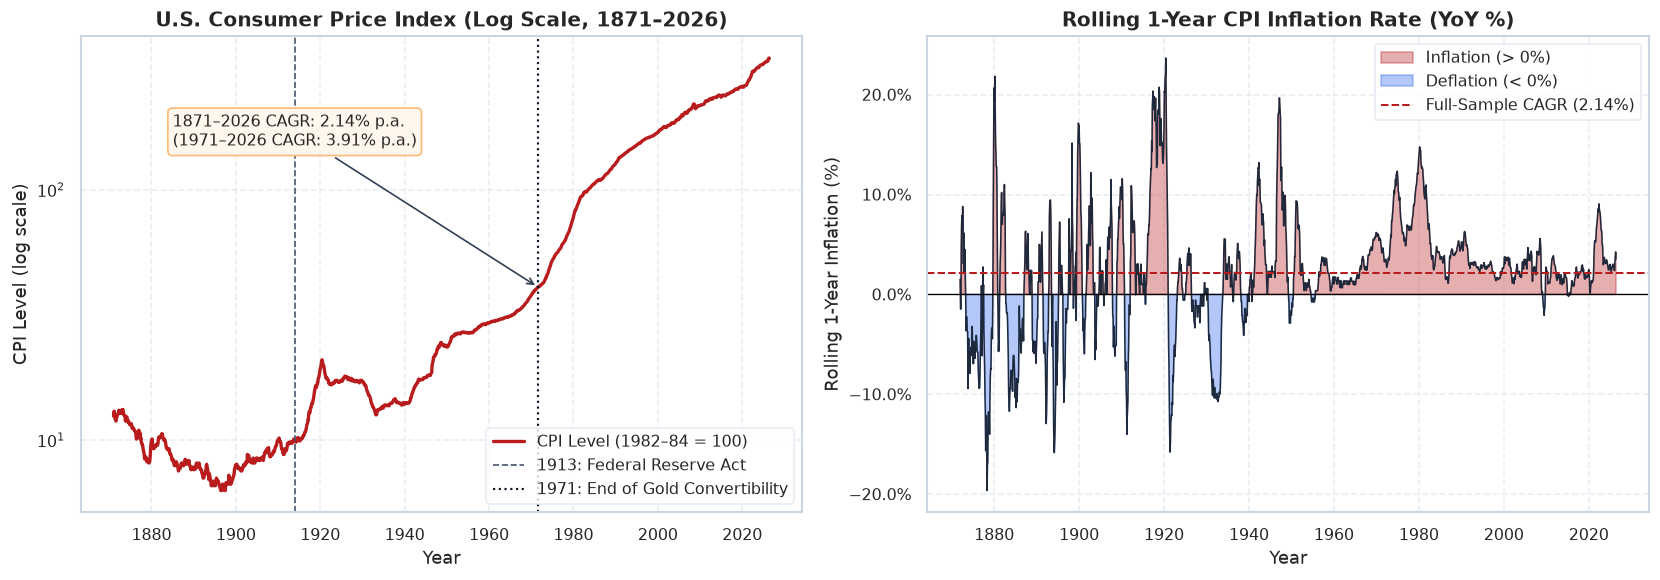

In [5]:
# Figure 01: CPI trajectory (linear vs log) and rolling 1-year inflation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(df.index, df["CPI"], color=eu.PALETTE["Inflation"], lw=2, label="CPI Level (1982–84 = 100)")
ax.set_yscale("log")
ax.axvline(pd.Timestamp("1913-12-01"), color="#475569", ls="--", lw=1, label="1913: Federal Reserve Act")
ax.axvline(pd.Timestamp("1971-08-01"), color="#0f172a", ls=":", lw=1.3, label="1971: End of Gold Convertibility")
ax.set_title("U.S. Consumer Price Index (Log Scale, 1871–2026)")
ax.set_ylabel("CPI Level (log scale)")
ax.set_xlabel("Year")
ax.annotate(
    f"1871–2026 CAGR: 2.14% p.a.\n(1971–2026 CAGR: 3.91% p.a.)",
    xy=(pd.Timestamp("1971-08-01"), df.loc["1971-08-01", "CPI"]),
    xytext=(pd.Timestamp("1885-01-01"), 150),
    arrowprops=dict(arrowstyle="->", color="#334155"),
    fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.3", fc="#fff7ed", ec="#fdba74"),
)
ax.legend(loc="lower right")

ax2 = axes[1]
yoy_pct = df["inf_1y"].dropna() * 100
ax2.fill_between(yoy_pct.index, yoy_pct, 0, where=(yoy_pct >= 0), color=eu.PALETTE["Inflation"], alpha=0.35, label="Inflation (> 0%)")
ax2.fill_between(yoy_pct.index, yoy_pct, 0, where=(yoy_pct < 0), color=eu.PALETTE["Deflation"], alpha=0.35, label="Deflation (< 0%)")
ax2.plot(yoy_pct.index, yoy_pct, color="#1e293b", lw=0.9)
ax2.axhline(2.14, color=eu.PALETTE["Inflation"], ls="--", lw=1.2, label="Full-Sample CAGR (2.14%)")
ax2.axhline(0, color="black", lw=0.8)
ax2.set_title("Rolling 1-Year CPI Inflation Rate (YoY %)")
ax2.set_ylabel("Rolling 1-Year Inflation (%)")
ax2.set_xlabel("Year")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.legend(loc="upper right")

fig.tight_layout()
eu.save_fig(fig, "01_cpi_trajectory_and_rolling_inflation")
plt.show()

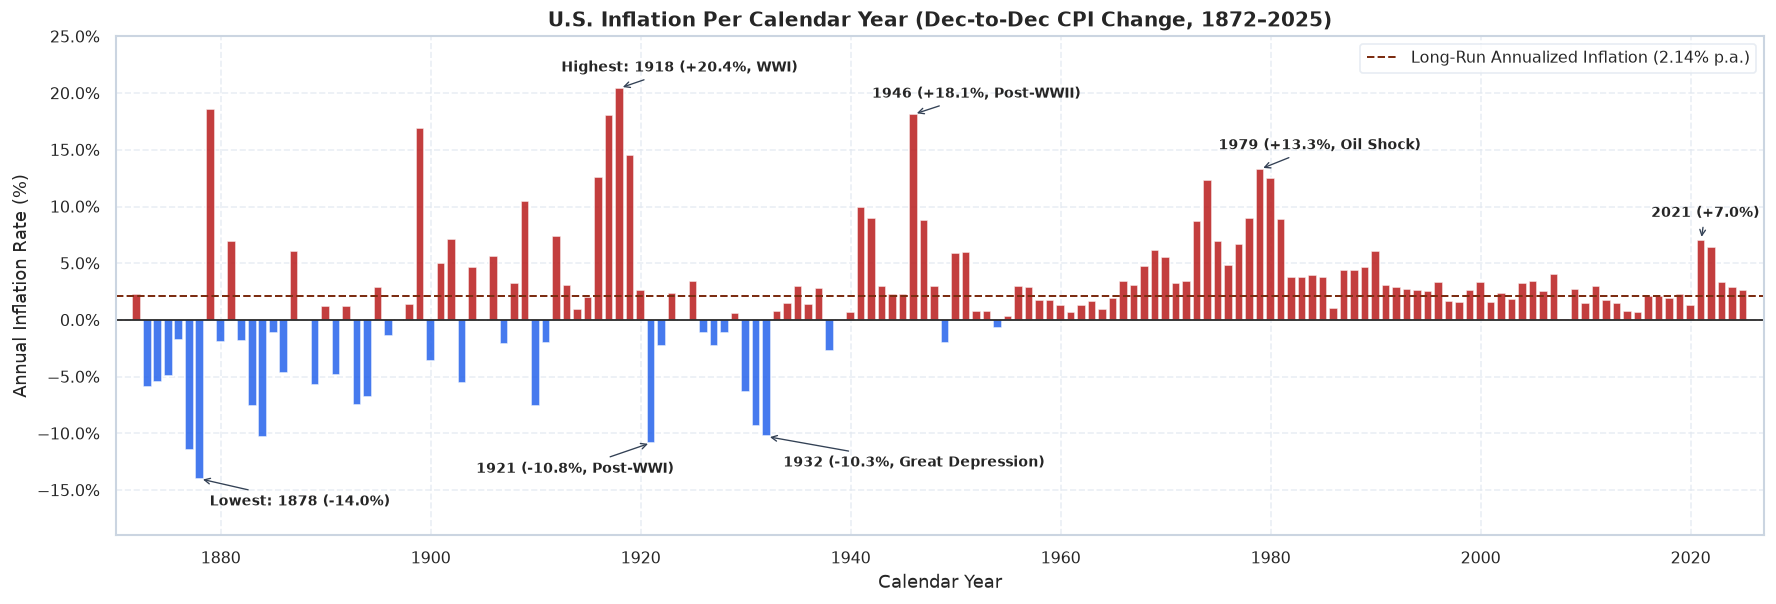

In [6]:
# Figure 02: Annual inflation per calendar year (1872-2025) with highest and lowest years annotated
fig, ax = plt.subplots(figsize=(15, 5.2))
colors = [eu.PALETTE["Inflation"] if v >= 0 else eu.PALETTE["Deflation"] for v in cal_inf.values]
ax.bar(cal_inf.index, cal_inf.values, color=colors, width=0.82, alpha=0.85)
ax.axhline(0, color="black", lw=0.9)
ax.axhline(2.14, color="#7c2d12", ls="--", lw=1.2, label="Long-Run Annualized Inflation (2.14% p.a.)")

# Annotate historical extremes
annotations = [
    (1918, cal_inf.loc[1918], "Highest: 1918 (+20.4%, WWI)", (-35, 10)),
    (1946, cal_inf.loc[1946], "1946 (+18.1%, Post-WWII)", (-25, 10)),
    (1979, cal_inf.loc[1979], "1979 (+13.3%, Oil Shock)", (-25, 12)),
    (2021, cal_inf.loc[2021], "2021 (+7.0%)", (-30, 14)),
    (1878, cal_inf.loc[1878], "Lowest: 1878 (-14.0%)", (6, -16)),
    (1921, cal_inf.loc[1921], "1921 (-10.8%, Post-WWI)", (-105, -18)),
    (1932, cal_inf.loc[1932], "1932 (-10.3%, Great Depression)", (10, -18)),
]
for yr, val, txt, offset in annotations:
    ax.annotate(
        txt,
        xy=(yr, val),
        xytext=offset,
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
        arrowprops=dict(arrowstyle="->", lw=0.8, color="#334155"),
    )

ax.set_title("U.S. Inflation Per Calendar Year (Dec-to-Dec CPI Change, 1872–2025)")
ax.set_xlabel("Calendar Year")
ax.set_ylabel("Annual Inflation Rate (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(1870, 2027)
ax.set_ylim(-19, 25)
ax.legend(loc="upper right")
fig.tight_layout()
eu.save_fig(fig, "02_annual_inflation_per_year")
plt.show()

**CPI & Inflation Findings:**
- **26.8× Price Level Expansion (`2.14%` p.a. since 1871):** What cost **\$1.00 in January 1871** costs **\$26.79 in June 2026**, corresponding to an annualized inflation rate of **2.14% p.a.** over 155.4 years. However, the log-scale CPI plot exposes a sharp **structural break**: under the Classical Gold Standard (1871–1913), inflation averaged **-0.48% p.a.** (mild deflation as industrial productivity grew), whereas since the end of Bretton Woods in August 1971, inflation averaged **3.91% p.a.** with virtually zero deflationary years!
- **Highest vs. Lowest Inflation Years:** The highest calendar-year inflation occurred in **1918 (+20.4% Dec/Dec; rolling peak +23.7% in June 1920)** during WWI monetization, **1879 (+18.6% Gold Resumption rebound)**, and **1946 (+18.1% post-WWII price decontrol)**, followed in modern times by **1979 (+13.3%)**, **1974 (+12.3%)**, and **2021 (+7.0%; rolling peak +9.1% in June 2022)**. The deepest deflations occurred in **1878 (-14.0%)**, **1921 (-10.8%)**, and **1932 (-10.3%, Great Depression)**.
- **Direct Consequence for Modeling:** Because nominal returns mix real wealth creation with huge monetary regime shifts (-14% deflation to +20% inflation), **predicting real (CPI-deflated) returns is essential** so models learn economic risk premia rather than inflation drift.

### 2.2 Univariate Graphical EDA of Returns, Valuation & Risk (`DEA-04` Toolkit)
Following *Lecture `DEA-04`*, no single plot tells the full distributional story—so we combine **KDE density overlays**, **violin + Tukey boxplots**, **normal Q-Q plots**, and **cumulative wealth / drawdown curves**.

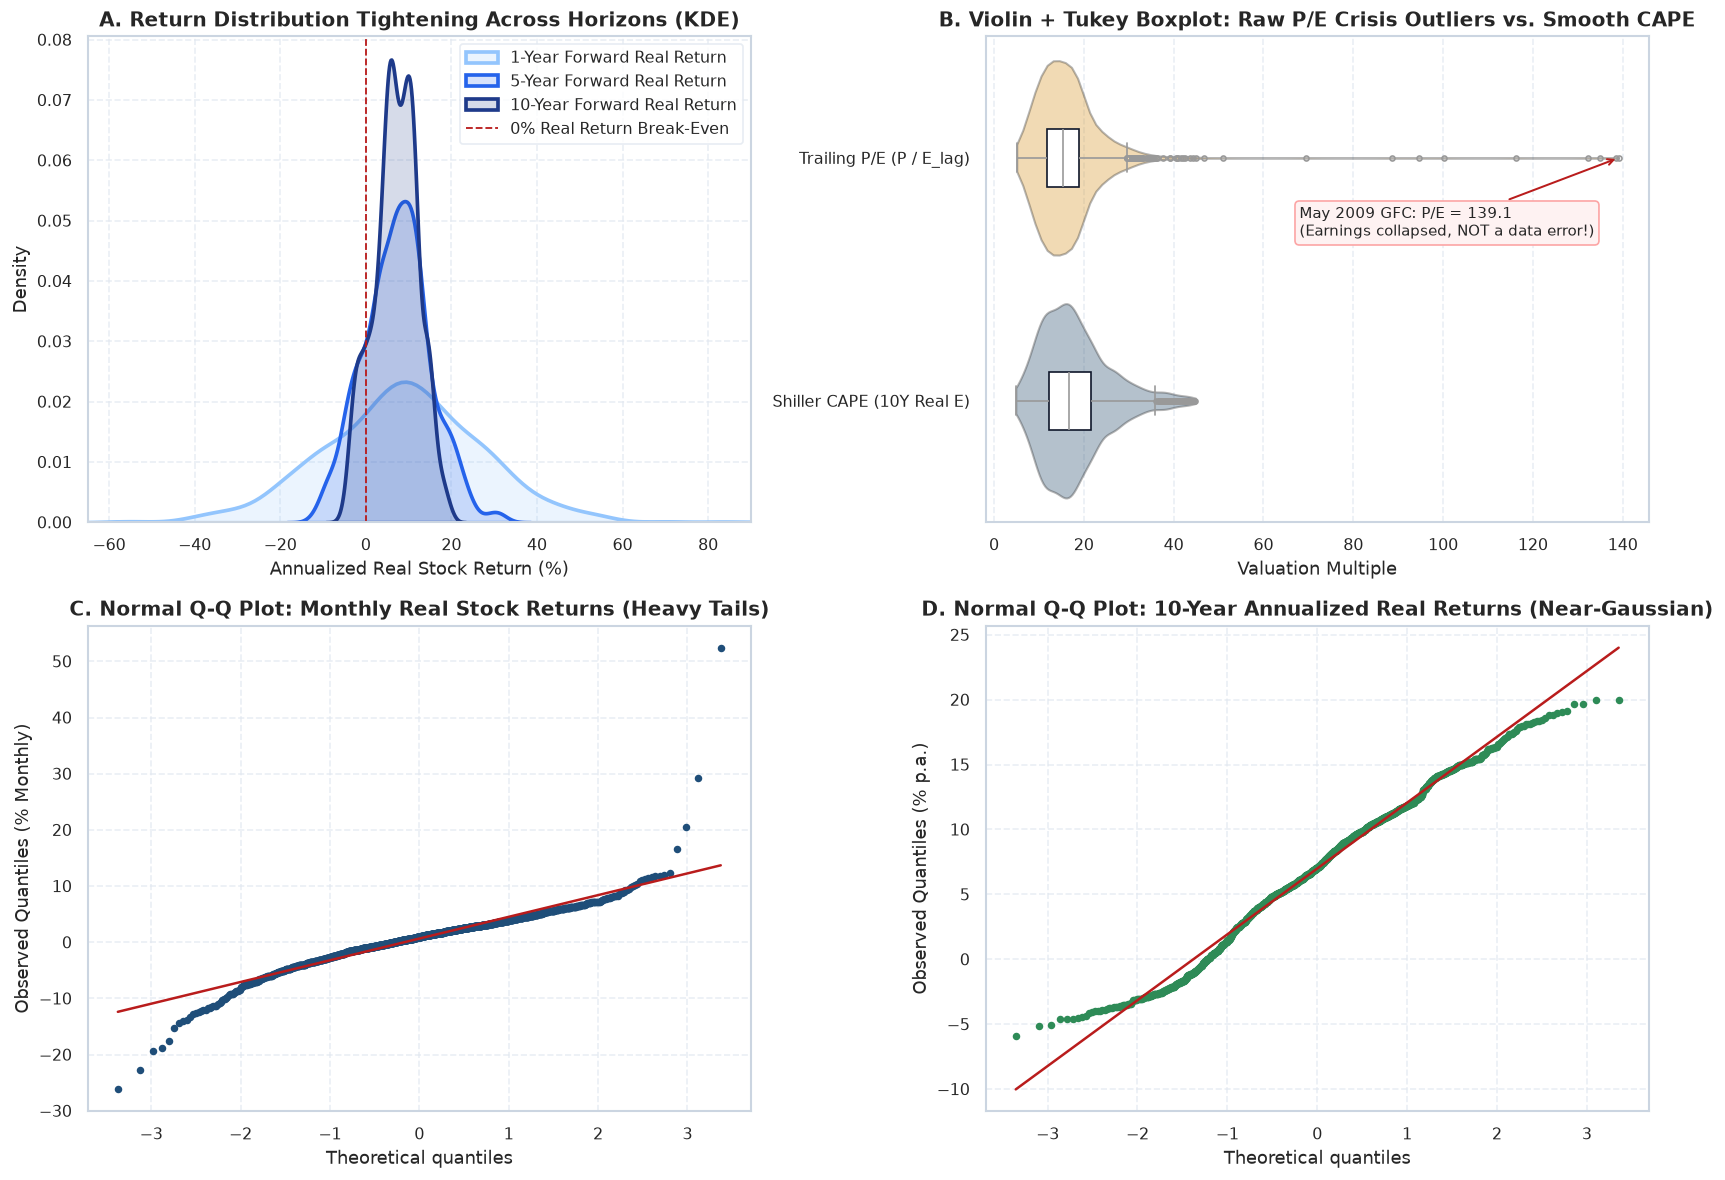

In [7]:
# Figure 03: DEA-04 Univariate Graphical EDA (KDEs across horizons, Violin/Boxplots of PE vs CAPE, Normal Q-Q Plots)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) KDE density comparison across 1Y, 5Y, 10Y annualized real stock returns
ax = axes[0, 0]
for col, lbl, clr in [
    ("fwd_ret_1y", "1-Year Forward Real Return", "#93c5fd"),
    ("fwd_ret_5y", "5-Year Forward Real Return", "#2563eb"),
    ("fwd_ret_10y", "10-Year Forward Real Return", "#1e3a8a"),
]:
    sns.kdeplot(df[col].dropna() * 100, ax=ax, lw=2.2, fill=True, alpha=0.18, color=clr, label=lbl)
ax.axvline(0, color="#b91c1c", ls="--", lw=1.1, label="0% Real Return Break-Even")
ax.set_xlim(-65, 90)
ax.set_title("A. Return Distribution Tightening Across Horizons (KDE)")
ax.set_xlabel("Annualized Real Stock Return (%)")
ax.set_ylabel("Density")
ax.legend()

# (b) Violin + Boxplot comparing P/E vs CAPE (highlighting the 2009 PE=139 outlier)
ax = axes[0, 1]
val_long = pd.concat([
    pd.DataFrame({"Metric": "Trailing P/E (P / E_lag)", "Ratio": df["pe"].dropna()}),
    pd.DataFrame({"Metric": "Shiller CAPE (10Y Real E)", "Ratio": df["cape"].dropna()}),
])
sns.violinplot(data=val_long, x="Ratio", y="Metric", hue="Metric", ax=ax, palette=["#f59e0b", "#1f4e79"], inner=None, alpha=0.35, cut=0, legend=False)
sns.boxplot(data=val_long, x="Ratio", y="Metric", ax=ax, width=0.24, color="white", fliersize=3, boxprops=dict(edgecolor="#0f172a"))
ax.annotate(
    "May 2009 GFC: P/E = 139.1\n(Earnings collapsed, NOT a data error!)",
    xy=(139.09, 0),
    xytext=(68, 0.32),
    arrowprops=dict(arrowstyle="->", color="#b91c1c", lw=1.2),
    fontsize=8.8,
    bbox=dict(boxstyle="round,pad=0.3", fc="#fef2f2", ec="#fca5a5"),
)
ax.set_title("B. Violin + Tukey Boxplot: Raw P/E Crisis Outliers vs. Smooth CAPE")
ax.set_xlabel("Valuation Multiple")
ax.set_ylabel("")

# (c) Normal Q-Q Plot of Monthly Real Stock Returns
ax = axes[1, 0]
probplot(df["ret_real"].dropna() * 100, dist="norm", plot=ax)
ax.get_lines()[0].set_color(eu.PALETTE["Stocks"])
ax.get_lines()[0].set_markersize(3.5)
ax.get_lines()[1].set_color(eu.PALETTE["Inflation"])
ax.set_title("C. Normal Q-Q Plot: Monthly Real Stock Returns (Heavy Tails)")
ax.set_ylabel("Observed Quantiles (% Monthly)")

# (d) Normal Q-Q Plot of 10-Year Annualized Real Stock Returns
ax = axes[1, 1]
probplot(df["fwd_ret_10y"].dropna() * 100, dist="norm", plot=ax)
ax.get_lines()[0].set_color(eu.PALETTE["10Y Gov Bonds"])
ax.get_lines()[0].set_markersize(3.5)
ax.get_lines()[1].set_color(eu.PALETTE["Inflation"])
ax.set_title("D. Normal Q-Q Plot: 10-Year Annualized Real Returns (Near-Gaussian)")
ax.set_ylabel("Observed Quantiles (% p.a.)")

fig.tight_layout()
eu.save_fig(fig, "03_univariate_distributions_kde_box_violin_qq")
plt.show()

<>:16: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:20: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:24: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:16: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:20: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:24: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
/tmp/ipykernel_6359/2899796438.py:16: SyntaxWarning: "\$" is an invalid esca

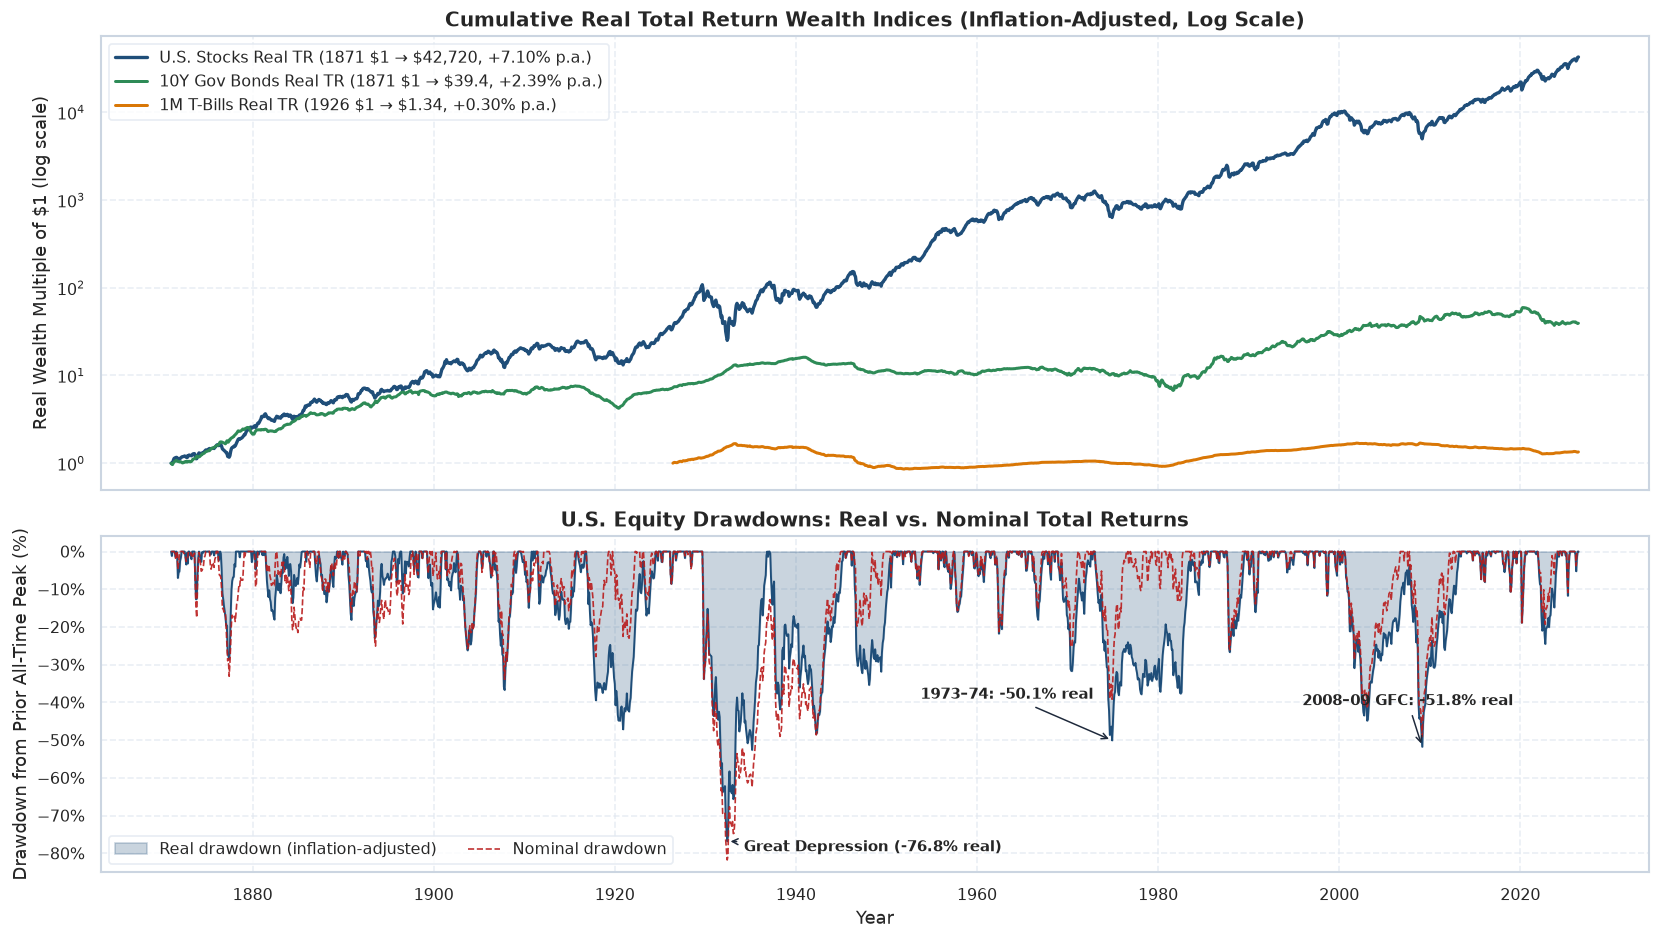

In [8]:
# Figure 04: Cumulative Real Wealth Across Asset Classes & Equity Underwater Drawdowns
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [1.35, 1]})

# Compound annualized real growth rates (solving (1 + r)^years = terminal_wealth)
years_full = (len(df) - 1) / 12.0  # Jan 1871 to Jun 2026 = 155.42 years (1,865 months)
tb_plot = df["tbill1m_tr_real"].dropna()
years_tbill = (len(tb_plot) - 1) / 12.0  # Jun 1926 to Jun 2026 = 100.00 years (1,200 months)

cagr_stocks = (df["tr_index"].iloc[-1] ** (1.0 / years_full) - 1.0) * 100
cagr_bonds = (df["bond10y_tr_real"].iloc[-1] ** (1.0 / years_full) - 1.0) * 100
cagr_tbills = (tb_plot.iloc[-1] ** (1.0 / years_tbill) - 1.0) * 100

ax = axes[0]
ax.plot(
    df.index, df["tr_index"], color=eu.PALETTE["Stocks"], lw=2.0,
    label=f"U.S. Stocks Real TR (1871 \$1 → \${df['tr_index'].iloc[-1]:,.0f}, +{cagr_stocks:.2f}% p.a.)",
)
ax.plot(
    df.index, df["bond10y_tr_real"], color=eu.PALETTE["10Y Gov Bonds"], lw=1.8,
    label=f"10Y Gov Bonds Real TR (1871 \$1 → \${df['bond10y_tr_real'].iloc[-1]:.1f}, +{cagr_bonds:.2f}% p.a.)",
)
ax.plot(
    tb_plot.index, tb_plot, color=eu.PALETTE["1M T-Bills"], lw=1.8,
    label=f"1M T-Bills Real TR (1926 \$1 → \${tb_plot.iloc[-1]:.2f}, +{cagr_tbills:.2f}% p.a.)",
)
ax.set_yscale("log")
ax.set_title("Cumulative Real Total Return Wealth Indices (Inflation-Adjusted, Log Scale)")
ax.set_ylabel("Real Wealth Multiple of $1 (log scale)")
ax.legend(loc="upper left")

ax2 = axes[1]
dd_real_pct = df["tr_index"].div(df["tr_index"].cummax()).sub(1.0).mul(100)
dd_nominal_pct = df["tr_index_nom"].div(df["tr_index_nom"].cummax()).sub(1.0).mul(100)
ax2.fill_between(
    df.index, dd_real_pct, 0, color=eu.PALETTE["Stocks"], alpha=0.24,
    label="Real drawdown (inflation-adjusted)",
)
ax2.plot(df.index, dd_real_pct, color=eu.PALETTE["Stocks"], lw=1.15)
ax2.plot(
    df.index, dd_nominal_pct, color=eu.PALETTE["Inflation"], lw=1.0,
    ls="--", alpha=0.9, label="Nominal drawdown",
)
for dt_str, label, xy_off in [
    ("1932-06-01", "Great Depression (-76.8% real)", (10, -6)),
    ("1974-12-01", "1973–74: -50.1% real", (-115, 25)),
    ("2009-03-01", "2008–09 GFC: -51.8% real", (-72, 25)),
]:
    ax2.annotate(
        label,
        xy=(pd.Timestamp(dt_str), dd_real_pct.loc[dt_str]),
        xytext=xy_off,
        textcoords="offset points",
        fontsize=8.8,
        fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="#1e293b", lw=0.9),
    )
ax2.set_title("U.S. Equity Drawdowns: Real vs. Nominal Total Returns")
ax2.set_ylabel("Drawdown from Prior All-Time Peak (%)")
ax2.set_xlabel("Year")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylim(-85, 4)
ax2.legend(loc="lower left", ncol=2)

fig.tight_layout()
eu.save_fig(fig, "04_real_wealth_and_drawdowns")
plt.show()

### 2.3 Drawdown Depth, Duration & Recovery (Nominal vs. Real)

The underwater curves compare the percentage loss from the **prior all-time high**. The tables below split each continuous drawdown into a distinct episode and report:
- **depth**: the maximum loss from the prior peak;
- **peak-to-trough time**: months needed to reach the lowest point;
- **recovery time**: months from trough until the former peak is regained; and
- **time underwater**: total time from the old peak to full recovery.

The nominal episode classification answers "when was the former dollar value regained?" while the real classification answers "when was purchasing power regained?" This distinction is essential during inflationary periods: nominal recovery can precede real recovery by years. Threshold counts use non-overlapping, distinct drawdown episodes and are cumulative (for example, a -50% drawdown also counts in the ≥20%, ≥30%, and ≥50% rows).

In [9]:
# 2.3a: Top 10 stock drawdown episodes and threshold frequencies
tr_indices = {
    "Real": df["tr_index"],
    "Nominal": df["tr_index_nom"],
}
all_episodes = {
    basis: eu.drawdown_episodes(series)
    for basis, series in tr_indices.items()
}

top10_frames = []
threshold_frames = []
for basis in ["Real", "Nominal"]:
    episodes = all_episodes[basis].sort_values("drawdown_pct").head(10).copy()
    episodes.insert(0, "return_basis", basis)
    episodes.insert(1, "rank", np.arange(1, len(episodes) + 1))
    for date_col in ["peak_date", "trough_date", "recovery_date"]:
        episodes[date_col] = pd.to_datetime(episodes[date_col]).dt.strftime("%Y-%m")
    top10_frames.append(episodes)

    thresholds = eu.drawdown_threshold_summary(all_episodes[basis])
    thresholds.insert(0, "return_basis", basis)
    threshold_frames.append(thresholds)

drawdown_top10 = pd.concat(top10_frames, ignore_index=True)
drawdown_threshold_table = pd.concat(threshold_frames, ignore_index=True)

eu.save_table(
    drawdown_top10,
    "04a_top10_stock_drawdowns_nominal_vs_real",
    title="Top 10 U.S. Stock Drawdown Episodes: Real vs. Nominal (1871–2026)",
    float_fmt="{:.2f}",
    index=False,
)
eu.save_table(
    drawdown_threshold_table,
    "04b_drawdown_threshold_frequency_real_vs_nominal",
    title="Frequency and Duration of Stock Drawdowns by Severity (1871–2026)",
    float_fmt="{:.2f}",
    index=False,
)

display(drawdown_top10)
display(drawdown_threshold_table)


,return_basis,rank,peak_date,trough_date,recovery_date,drawdown_pct,peak_to_trough_months,trough_to_recovery_months,underwater_months,underwater_years,recovered,description
0,Real,1,1929-09,1932-06,1936-11,-76.797437,33,53,86,7.166667,True,Great Depression
1,Real,2,2000-08,2009-03,2013-05,-51.758596,103,50,153,12.750000,True,Dot-com crash through Global Financial Crisis
2,Real,3,1973-01,1974-12,1985-01,-50.059362,23,121,144,12.000000,True,1973–74 oil shock and stagflation
3,Real,4,1937-02,1942-04,1945-04,-48.312078,62,36,98,8.166667,True,1937 recession through World War II
4,Real,5,1916-11,1920-12,1924-08,-47.127229,49,44,93,7.750000,True,World War I and post-war market stress
5,Real,6,1906-09,1907-11,1909-05,-36.703600,14,18,32,2.666667,True,Panic of 1907
6,Real,7,1946-04,1948-02,1950-10,-35.376704,22,32,54,4.500000,True,Post-war inflation / recession episodes
7,Real,8,1968-12,1970-06,1972-11,-31.666360,18,29,47,3.916667,True,1966–69 inflationary bear market
8,Real,9,1876-06,1877-06,1878-03,-28.534503,12,9,21,1.750000,True,Panic of 1873 / Long Depression
9,Real,10,1987-08,1987-12,1989-08,-26.678286,4,20,24,2.000000,True,1980–82 recession / 1987 crash


,return_basis,drawdown_threshold_pct,episode_count,mean_underwater_years,median_underwater_years,max_underwater_years,mean_drawdown_pct,worst_drawdown_pct
0,Real,10.0,30,3.216667,2.000000,12.750000,-25.533814,-76.797437
1,Real,20.0,15,5.088889,3.916667,12.750000,-36.594085,-76.797437
2,Real,30.0,8,7.364583,7.458333,12.750000,-47.225171,-76.797437
3,Real,50.0,3,10.638889,12.000000,12.750000,-59.538465,-76.797437
4,Nominal,10.0,31,2.559140,2.000000,15.333333,-23.252903,-81.759835
5,Nominal,20.0,14,3.946429,2.708333,15.333333,-33.870888,-81.759835
6,Nominal,30.0,6,5.833333,4.166667,15.333333,-46.411251,-81.759835
7,Nominal,50.0,1,15.333333,15.333333,15.333333,-81.759835,-81.759835


---
## 3. Holding-Period Win Probabilities, Term Premium & Equity Risk Premium

### 3.1 Probability of Positive Returns & Return Ranges Across Horizons (1Y, 5Y, 10Y, 15Y, 20Y)
How risky is each holding horizon, and how do **Stocks**, **10-Year Government Bonds**, and **1-Month Treasury Bills** compare in terms of:
1. **Probability of a positive return** after $X$ years (contrasting **real purchasing power** vs. **nominal** "cash illusion"), and
2. **Average, median, minimum, IQR, and maximum** annualized returns over $X$ years?

In [10]:
# Compute multi-horizon summary tables (Full Sample 1871-2026 and Matched Sample 1926-2026, Real & Nominal)
horizons_list = [1, 3, 5, 10, 15, 20]
mh_real_all = eu.multi_horizon_asset_summary(df, horizons=horizons_list, start_date=None, real=True)
mh_real_1926 = eu.multi_horizon_asset_summary(df, horizons=horizons_list, start_date="1926-06-01", real=True)
mh_nom_1926 = eu.multi_horizon_asset_summary(df, horizons=horizons_list, start_date="1926-06-01", real=False)

eu.save_table(mh_real_all, "04_multi_horizon_asset_returns_real_full", title="Multi-Horizon Real Return Summary Across Assets (Full Available History)", float_fmt="{:.2f}", index=False)
eu.save_table(mh_real_1926, "05_multi_horizon_asset_returns_real_matched_1926", title="Multi-Horizon Real Return Summary Across Assets (Matched Sample: 1926–2026)", float_fmt="{:.2f}", index=False)

# Focus display on key project horizons: 1Y, 5Y, 10Y (plus 20Y context)
display(mh_real_all[mh_real_all["horizon_years"].isin([1, 5, 10, 20])].round(2))

,horizon_years,asset,n_windows,prob_positive_pct,mean_ann_pct,median_ann_pct,std_ann_pct,iqr_ann_pct,min_ann_pct,max_ann_pct,median_terminal_wealth_per_1usd,mean_terminal_wealth_per_1usd
0,1,Stocks,1854,69.58,8.75,8.83,19.15,23.76,-58.12,151.31,1.09,1.09
1,1,10Y Gov Bonds,1854,63.81,2.77,2.47,8.77,10.86,-22.94,41.22,1.02,1.03
2,1,1M T-Bills,1189,58.37,0.35,0.51,3.78,3.53,-16.14,13.38,1.01,1.00
6,5,Stocks,1806,81.34,7.23,7.39,7.78,9.91,-13.23,33.35,1.43,1.49
7,5,10Y Gov Bonds,1806,68.72,2.51,2.23,4.78,6.22,-10.83,18.79,1.12,1.16
8,5,1M T-Bills,1141,52.15,0.20,0.27,2.74,2.96,-6.30,8.85,1.01,1.02
9,10,Stocks,1746,88.95,6.99,7.02,5.09,6.77,-5.92,19.96,1.97,2.17
10,10,10Y Gov Bonds,1746,71.65,2.42,1.89,3.58,6.06,-5.42,10.98,1.21,1.34
11,10,1M T-Bills,1081,53.10,0.08,0.29,2.14,2.90,-5.30,4.38,1.03,1.03
15,20,Stocks,1626,99.94,6.66,6.83,2.90,3.94,-0.22,13.61,3.75,4.17


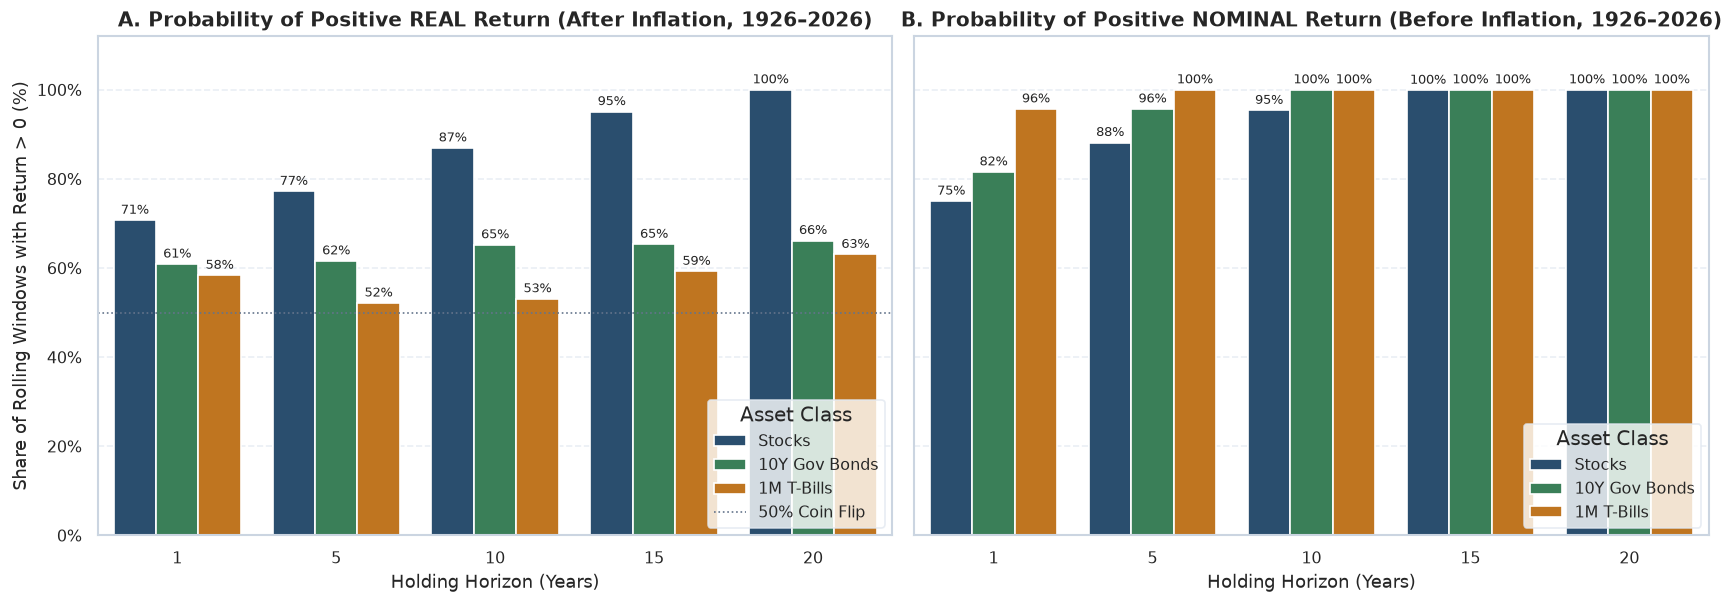

In [11]:
# Figure 05: Probability of Positive Return after 1, 3, 5, 10, 15, 20 Years (Real vs Nominal Cash Illusion)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2), sharey=True)

# Left: Real Win Probability (Matched 1926-2026 sample so all 3 assets cover identical macro history)
ax = axes[0]
key_h = [1, 5, 10, 15, 20]
sub_r = mh_real_1926[mh_real_1926["horizon_years"].isin(key_h)]
sns.barplot(
    data=sub_r, x="horizon_years", y="prob_positive_pct", hue="asset",
    palette=eu.PALETTE, ax=ax, edgecolor="white"
)
ax.axhline(50, color="#64748b", ls=":", lw=1, label="50% Coin Flip")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", fontsize=8, padding=2)
ax.set_title("A. Probability of Positive REAL Return (After Inflation, 1926–2026)")
ax.set_xlabel("Holding Horizon (Years)")
ax.set_ylabel("Share of Rolling Windows with Return > 0 (%)")
ax.set_ylim(0, 112)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc="lower right", title="Asset Class")

# Right: Nominal Win Probability (Matched 1926-2026) -> Exposes 'Cash Illusion'!
ax2 = axes[1]
sub_n = mh_nom_1926[mh_nom_1926["horizon_years"].isin(key_h)]
sns.barplot(
    data=sub_n, x="horizon_years", y="prob_positive_pct", hue="asset",
    palette=eu.PALETTE, ax=ax2, edgecolor="white"
)
for container in ax2.containers:
    ax2.bar_label(container, fmt="%.0f%%", fontsize=8, padding=2)
ax2.set_title("B. Probability of Positive NOMINAL Return (Before Inflation, 1926–2026)")
ax2.set_xlabel("Holding Horizon (Years)")
ax2.legend(loc="lower right", title="Asset Class")

fig.tight_layout()
eu.save_fig(fig, "05_win_probabilities_by_horizon")
plt.show()

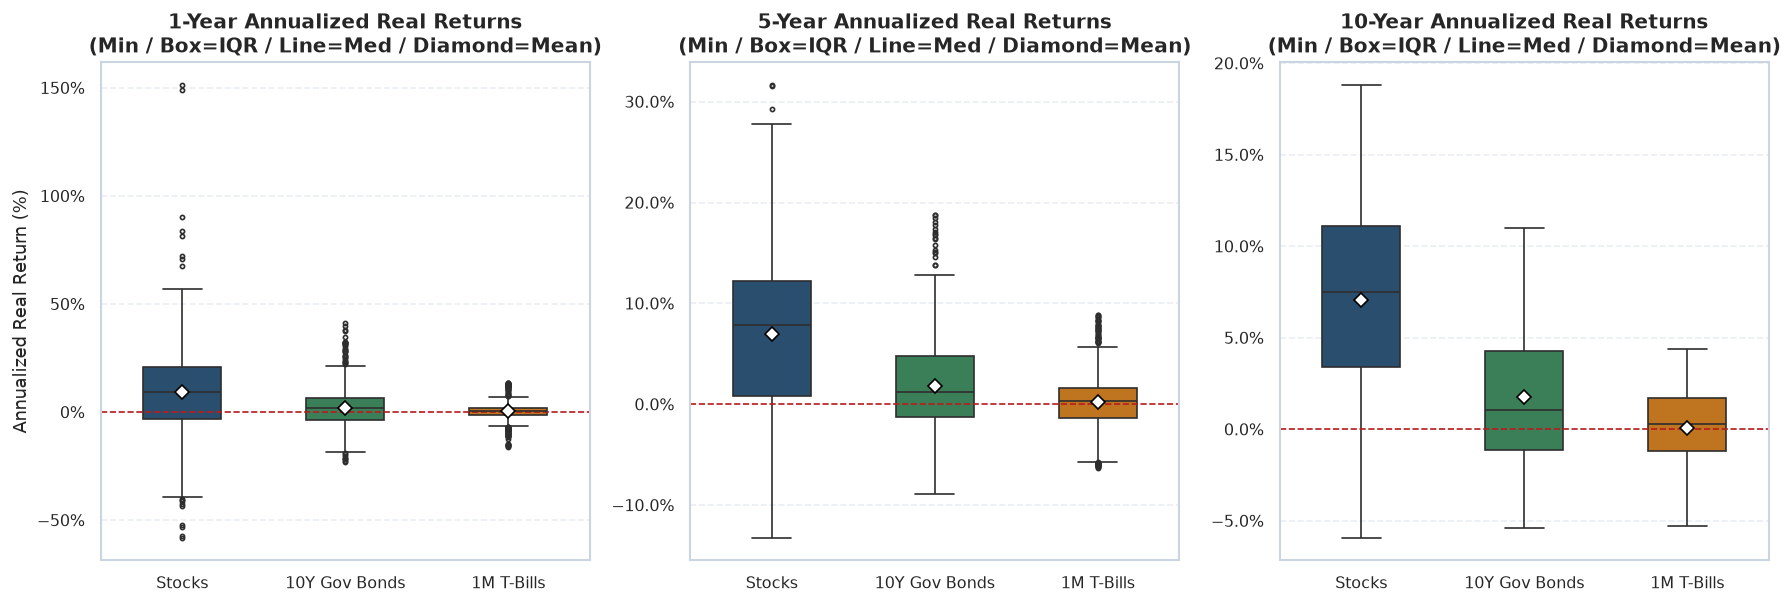

In [12]:
# Figure 06: Average, Median, IQR, and Min/Max Annualized Real Returns Across 1Y, 5Y, and 10Y Horizons
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=False)

for idx, yrs in enumerate([1, 5, 10]):
    ax = axes[idx]
    s_ret = eu.forward_annualized_return(df["tr_index"], yrs).loc["1926-06-01":].dropna() * 100
    b_ret = eu.forward_annualized_return(df["bond10y_tr_real"], yrs).loc["1926-06-01":].dropna() * 100
    t_ret = eu.forward_annualized_return(df["tbill1m_tr_real"], yrs).loc["1926-06-01":].dropna() * 100
    long_h = pd.concat([
        pd.DataFrame({"Asset": "Stocks", "Return": s_ret}),
        pd.DataFrame({"Asset": "10Y Gov Bonds", "Return": b_ret}),
        pd.DataFrame({"Asset": "1M T-Bills", "Return": t_ret}),
    ])
    sns.boxplot(
        data=long_h, x="Asset", y="Return", hue="Asset", palette=eu.PALETTE,
        ax=ax, width=0.48, showmeans=True,
        meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6),
        fliersize=2.5, legend=False,
    )
    ax.axhline(0, color="#b91c1c", ls="--", lw=1.0)
    ax.set_title(f"{yrs}-Year Annualized Real Returns\n(Min / Box=IQR / Line=Med / Diamond=Mean)")
    ax.set_xlabel("")
    ax.set_ylabel("Annualized Real Return (%)" if idx == 0 else "")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())

fig.tight_layout()
eu.save_fig(fig, "06_return_ranges_by_horizon")
plt.show()

**Insights on Holding-Period Win Probabilities & Return Ranges:**
- **The "Cash Illusion" of 1-Month T-Bills:** Nominally (Panel B), 1-month Treasury bills look completely risk-free (`99.7%–100%` positive nominal returns at 1Y–20Y). **After inflation (Panel A)**, 1M T-bills preserve purchasing power in only **58.4% of 1-year windows**, **52.1% of 5-year windows**, and **53.1% of 10-year windows**—barely a coin flip! Their real 10-year return ranges from **-5.3% p.a.** (1940s/1970s financial repression) to **+4.4% p.a.** (1980s Volcker disinflation), with a 10-year median of just **+0.29% p.a.**.
- **Equity Horizon De-Risking:** In real terms, U.S. stocks win **69.6%** of the time over 1 year (`70.7%` post-1926), **81.3%** over 5 years (`77.2%` post-1926), **88.9%** over 10 years (`87.0%` post-1926), and **99.9%** over 20 years (with worst-to-best annualized ranges narrowing dramatically from **-58.1% to +151.3%** at 1Y down to **-5.9% to +20.0% p.a.** at 10Y).

---
### 3.2 Term Premium: 10-Year Bonds vs. Rolling 1-Month T-Bills Over 10 Years (& Testing the 1926–1981 Negative Term Premium)
Suppose at any month $t$ since June 1926, Investor A rolls over **1-month Treasury bills** for 10 years while Investor B stays invested in **10-year U.S. government bonds** for 10 years:
- After 10 years, **who was better off, how often, and by how much?**
- **Was the realized term premium really negative from 1926 until 1981?**

In [13]:
# Compute exact 1926-1981 regime test AND rolling 10-year Term Premium & Equity Risk Premium comparisons
b10_ann = eu.forward_annualized_return(df["bond10y_tr_real"], 10)
t10_ann = eu.forward_annualized_return(df["tbill1m_tr_real"], 10)
s10_ann = eu.forward_annualized_return(df["tr_index"], 10)

b10_wealth = 1.0 + eu.forward_cumulative_return(df["bond10y_tr_real"], 10)
t10_wealth = 1.0 + eu.forward_cumulative_return(df["tbill1m_tr_real"], 10)
s10_wealth = 1.0 + eu.forward_cumulative_return(df["tr_index"], 10)

comp10 = pd.DataFrame({
    "stock_10y_ann": s10_ann,
    "bond10y_10y_ann": b10_ann,
    "tbill1m_10y_ann": t10_ann,
    "term_premium_pa": b10_ann - t10_ann,
    "erp_pa": s10_ann - t10_ann,
    "stock_wealth_100": s10_wealth * 100,
    "bond10y_wealth_100": b10_wealth * 100,
    "tbill1m_wealth_100": t10_wealth * 100,
    "bond_minus_tbill_100": (b10_wealth - t10_wealth) * 100,
    "stock_minus_tbill_100": (s10_wealth - t10_wealth) * 100,
}).dropna()

# Check cumulative point-to-point eras (1926-06 to 1981-09 peak yield, 1981-09 to 2020-07 trough yield, 2020-07 to 2026-06)
era_tp_rows = []
for name, d0, d1 in [
    ("1926-06 to 1981-09 (Rising-Yield Era to 15.32% Peak)", "1926-06-01", "1981-09-01"),
    ("1941-01 to 1981-09 (40-Year Bond Bear Market)", "1941-01-01", "1981-09-01"),
    ("1981-09 to 2020-07 (Secular Falling-Yield Bull Market)", "1981-09-01", "2020-07-01"),
    ("2020-07 to 2026-06 (Post-COVID Rate Reset)", "2020-07-01", "2026-06-01"),
    ("Full 100 Years: 1926-06 to 2026-06", "1926-06-01", "2026-06-01"),
]:
    n_m = (pd.Timestamp(d1).year - pd.Timestamp(d0).year) * 12 + (pd.Timestamp(d1).month - pd.Timestamp(d0).month)
    yrs = n_m / 12.0
    b_mult_real = df.loc[d1, "bond10y_tr_real"] / df.loc[d0, "bond10y_tr_real"]
    t_mult_real = df.loc[d1, "tbill1m_tr_real"] / df.loc[d0, "tbill1m_tr_real"]
    s_mult_real = df.loc[d1, "tr_index"] / df.loc[d0, "tr_index"]
    b_cagr = b_mult_real ** (1 / yrs) - 1
    t_cagr = t_mult_real ** (1 / yrs) - 1
    s_cagr = s_mult_real ** (1 / yrs) - 1
    era_tp_rows.append({
        "regime_window": name,
        "years": round(yrs, 2),
        "tbill_real_1usd": round(float(t_mult_real), 2),
        "bond10y_real_1usd": round(float(b_mult_real), 2),
        "stocks_real_1usd": round(float(s_mult_real), 2),
        "tbill_real_cagr_pct": round(float(t_cagr * 100), 2),
        "bond10y_real_cagr_pct": round(float(b_cagr * 100), 2),
        "realized_term_premium_pa_pct": round(float((b_cagr - t_cagr) * 100), 2),
        "realized_erp_pa_pct": round(float((s_cagr - t_cagr) * 100), 2),
    })

era_tp_df = pd.DataFrame(era_tp_rows)
eu.save_table(era_tp_df, "06a_regime_term_premium_1926_2026", title="Point-to-Point Realized Term Premium and ERP Across Interest-Rate Regimes", float_fmt="{:.2f}", index=False)

# Summary of all 1,081 rolling 10-year horizons (starts 1926-06 to 2016-06)
roll10_summary = pd.DataFrame([
    {
        "comparison_10y_horizon": "Term Premium: 10Y Bonds vs. 1M T-Bills (All 1926–2016 starts)",
        "n_10y_windows": len(comp10),
        "win_rate_pct": (comp10["term_premium_pa"] > 0).mean() * 100,
        "mean_spread_pa_pct": comp10["term_premium_pa"].mean() * 100,
        "median_spread_pa_pct": comp10["term_premium_pa"].median() * 100,
        "min_spread_pa_pct": comp10["term_premium_pa"].min() * 100,
        "max_spread_pa_pct": comp10["term_premium_pa"].max() * 100,
        "mean_10y_real_gain_per_100usd": comp10["bond_minus_tbill_100"].mean(),
        "median_10y_real_gain_per_100usd": comp10["bond_minus_tbill_100"].median(),
    },
    {
        "comparison_10y_horizon": "Term Premium: Pre-Peak Starts (1926–1971, ending <= 1981)",
        "n_10y_windows": len(comp10.loc[:"1971-09-01"]),
        "win_rate_pct": (comp10.loc[:"1971-09-01", "term_premium_pa"] > 0).mean() * 100,
        "mean_spread_pa_pct": comp10.loc[:"1971-09-01", "term_premium_pa"].mean() * 100,
        "median_spread_pa_pct": comp10.loc[:"1971-09-01", "term_premium_pa"].median() * 100,
        "min_spread_pa_pct": comp10.loc[:"1971-09-01", "term_premium_pa"].min() * 100,
        "max_spread_pa_pct": comp10.loc[:"1971-09-01", "term_premium_pa"].max() * 100,
        "mean_10y_real_gain_per_100usd": comp10.loc[:"1971-09-01", "bond_minus_tbill_100"].mean(),
        "median_10y_real_gain_per_100usd": comp10.loc[:"1971-09-01", "bond_minus_tbill_100"].median(),
    },
    {
        "comparison_10y_horizon": "Term Premium: Disinflation Starts (1981–2016, ending <= 2026)",
        "n_10y_windows": len(comp10.loc["1981-09-01":]),
        "win_rate_pct": (comp10.loc["1981-09-01":, "term_premium_pa"] > 0).mean() * 100,
        "mean_spread_pa_pct": comp10.loc["1981-09-01":, "term_premium_pa"].mean() * 100,
        "median_spread_pa_pct": comp10.loc["1981-09-01":, "term_premium_pa"].median() * 100,
        "min_spread_pa_pct": comp10.loc["1981-09-01":, "term_premium_pa"].min() * 100,
        "max_spread_pa_pct": comp10.loc["1981-09-01":, "term_premium_pa"].max() * 100,
        "mean_10y_real_gain_per_100usd": comp10.loc["1981-09-01":, "bond_minus_tbill_100"].mean(),
        "median_10y_real_gain_per_100usd": comp10.loc["1981-09-01":, "bond_minus_tbill_100"].median(),
    },
    {
        "comparison_10y_horizon": "Equity Risk Premium (ERP): Stocks vs. 1M T-Bills (All 1926–2016 starts)",
        "n_10y_windows": len(comp10),
        "win_rate_pct": (comp10["erp_pa"] > 0).mean() * 100,
        "mean_spread_pa_pct": comp10["erp_pa"].mean() * 100,
        "median_spread_pa_pct": comp10["erp_pa"].median() * 100,
        "min_spread_pa_pct": comp10["erp_pa"].min() * 100,
        "max_spread_pa_pct": comp10["erp_pa"].max() * 100,
        "mean_10y_real_gain_per_100usd": comp10["stock_minus_tbill_100"].mean(),
        "median_10y_real_gain_per_100usd": comp10["stock_minus_tbill_100"].median(),
    },
])
eu.save_table(roll10_summary, "06b_rolling_10y_term_premium_and_erp", title="Rolling 10-Year Investment Outcomes: 10Y Bonds & Stocks vs. 1M T-Bills", float_fmt="{:.2f}", index=False)

display(era_tp_df)
display(roll10_summary.round(2))

,regime_window,years,tbill_real_1usd,bond10y_real_1usd,stocks_real_1usd,tbill_real_cagr_pct,bond10y_real_cagr_pct,realized_term_premium_pa_pct,realized_erp_pa_pct
0,1926-06 to 1981-09 (Rising-Yield Era to 15.32%...,55.25,0.95,0.93,23.89,-0.09,-0.13,-0.05,6.00
1,1941-01 to 1981-09 (40-Year Bond Bear Market),40.67,0.63,0.42,10.16,-1.12,-2.12,-1.01,6.98
2,1981-09 to 2020-07 (Secular Falling-Yield Bull...,38.83,1.53,8.77,25.61,1.10,5.75,4.65,7.61
3,2020-07 to 2026-06 (Post-COVID Rate Reset),5.92,0.92,0.67,1.96,-1.35,-6.64,-5.28,13.40
4,Full 100 Years: 1926-06 to 2026-06,100.00,1.34,5.43,1199.00,0.30,1.71,1.41,7.05


,comparison_10y_horizon,n_10y_windows,win_rate_pct,mean_spread_pa_pct,median_spread_pa_pct,min_spread_pa_pct,max_spread_pa_pct,mean_10y_real_gain_per_100usd,median_10y_real_gain_per_100usd
0,Term Premium: 10Y Bonds vs. 1M T-Bills (All 19...,1081,70.31,1.68,1.97,-4.54,7.29,22.62,19.05
1,"Term Premium: Pre-Peak Starts (1926–1971, endi...",544,56.80,0.62,0.23,-4.46,3.85,7.02,2.33
2,"Term Premium: Disinflation Starts (1981–2016, ...",418,89.95,3.32,3.52,-1.92,7.29,44.61,42.73
3,Equity Risk Premium (ERP): Stocks vs. 1M T-Bil...,1081,85.57,6.96,7.07,-6.44,19.04,116.41,103.58


<>:15: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:33: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:15: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:33: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
/tmp/ipykernel_6359/1726382379.py:15: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
  "Sep 1981 (GS10 Peak = 15.32%):\n1M T-Bills: \$0.95 real (\$5.02 nom)\n10Y Bonds: \$0.93 real (\$4.90 nom)",
/tmp/ipykernel_6359/1726382379.py:33: SyntaxWarning: "\$" is an invalid escape sequence.

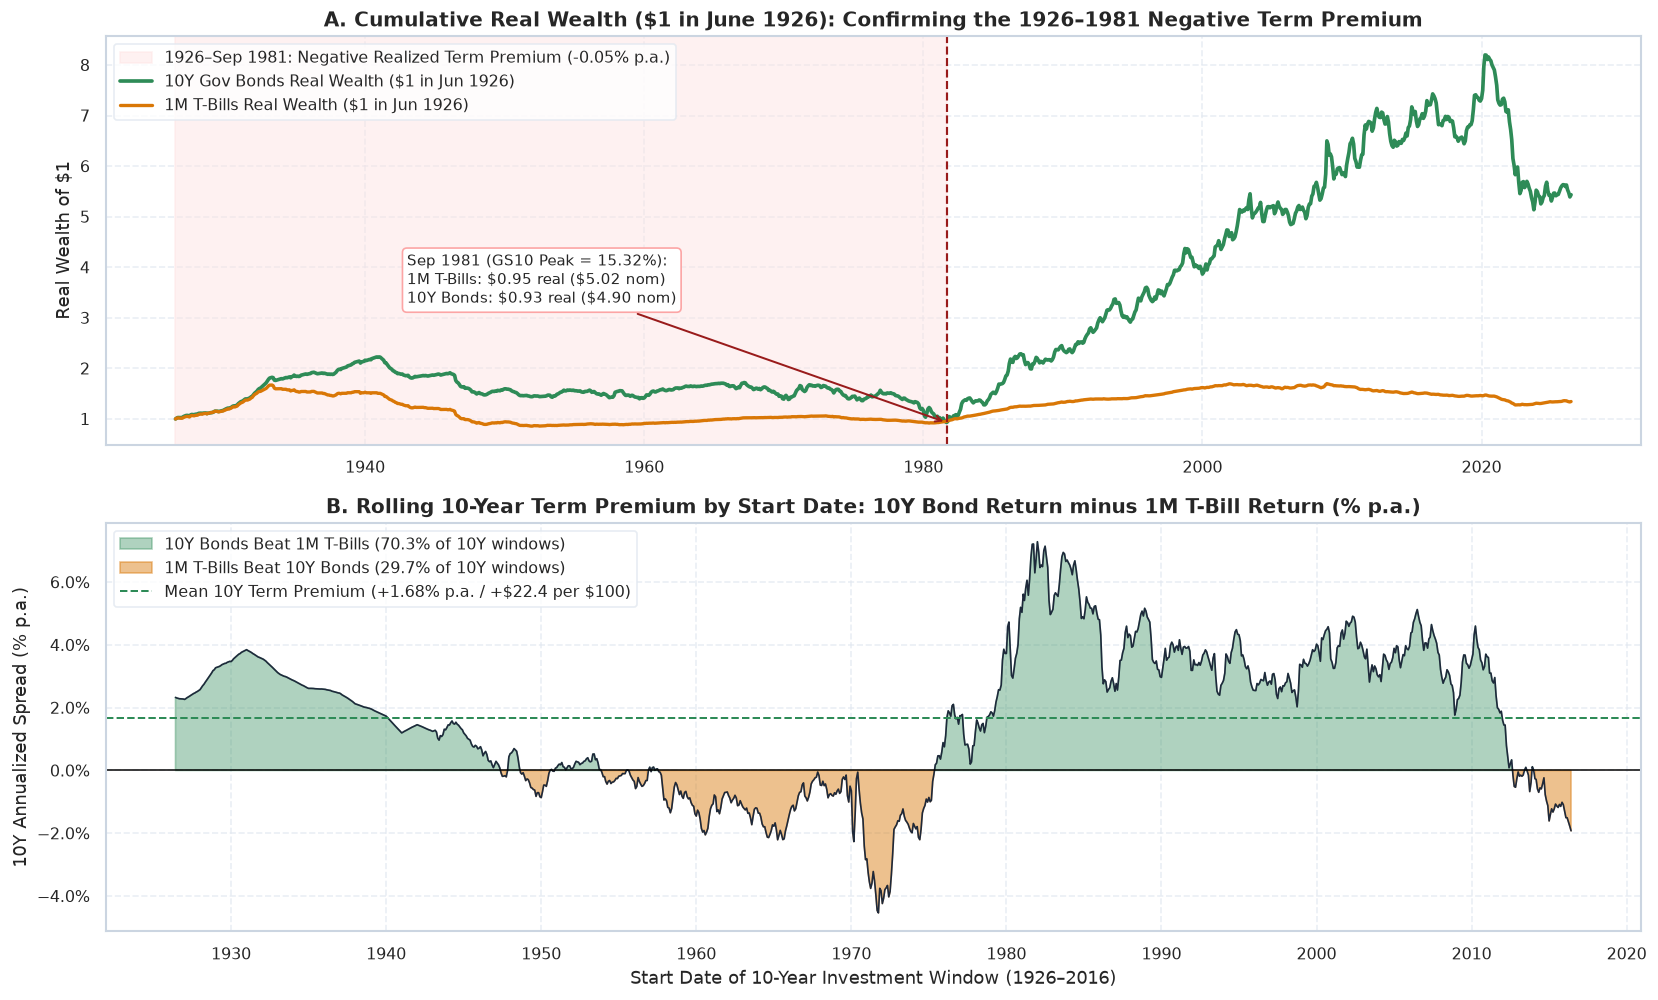

In [14]:
# Figure 07: Term Premium Analysis — 1926-1981 Negative Term Premium & Rolling 10-Year Bond vs T-Bill Outcomes
fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), sharex=False)

# Top panel: Cumulative Real Growth of $1 from June 1926 in 10Y Bonds vs 1M T-Bills (with GS10 on twin axis)
sub26 = df.loc["1926-06-01":].copy()
sub26["bond_rebased"] = sub26["bond10y_tr_real"] / sub26["bond10y_tr_real"].iloc[0]
sub26["tbill_rebased"] = sub26["tbill1m_tr_real"] / sub26["tbill1m_tr_real"].iloc[0]

ax = axes[0]
ax.axvspan(pd.Timestamp("1926-06-01"), pd.Timestamp("1981-09-01"), color="#fee2e2", alpha=0.45, label="1926–Sep 1981: Negative Realized Term Premium (-0.05% p.a.)")
ax.plot(sub26.index, sub26["bond_rebased"], color=eu.PALETTE["10Y Gov Bonds"], lw=2.2, label="10Y Gov Bonds Real Wealth ($1 in Jun 1926)")
ax.plot(sub26.index, sub26["tbill_rebased"], color=eu.PALETTE["1M T-Bills"], lw=2.0, label="1M T-Bills Real Wealth ($1 in Jun 1926)")
ax.axvline(pd.Timestamp("1981-09-01"), color="#991b1b", ls="--", lw=1.3)
ax.annotate(
    "Sep 1981 (GS10 Peak = 15.32%):\n1M T-Bills: \$0.95 real (\$5.02 nom)\n10Y Bonds: \$0.93 real (\$4.90 nom)",
    xy=(pd.Timestamp("1981-09-01"), sub26.loc["1981-09-01", "bond_rebased"]),
    xytext=(pd.Timestamp("1943-01-01"), 3.3),
    arrowprops=dict(arrowstyle="->", color="#991b1b", lw=1.2),
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#fca5a5"),
)
ax.set_title("A. Cumulative Real Wealth ($1 in June 1926): Confirming the 1926–1981 Negative Term Premium")
ax.set_ylabel("Real Wealth of $1")
ax.legend(loc="upper left")

# Bottom panel: Rolling 10-Year Annualized Term Premium (10Y Bond - 1M T-Bill, plotted by 10Y start date)
ax2 = axes[1]
tp_pct = comp10["term_premium_pa"] * 100
ax2.fill_between(tp_pct.index, tp_pct, 0, where=(tp_pct >= 0), color=eu.PALETTE["10Y Gov Bonds"], alpha=0.38, label="10Y Bonds Beat 1M T-Bills (70.3% of 10Y windows)")
ax2.fill_between(tp_pct.index, tp_pct, 0, where=(tp_pct < 0), color=eu.PALETTE["1M T-Bills"], alpha=0.45, label="1M T-Bills Beat 10Y Bonds (29.7% of 10Y windows)")
ax2.plot(tp_pct.index, tp_pct, color="#1e293b", lw=1.0)
ax2.axhline(0, color="black", lw=0.9)
ax2.axhline(tp_pct.mean(), color=eu.PALETTE["10Y Gov Bonds"], ls="--", lw=1.2, label=f"Mean 10Y Term Premium (+{tp_pct.mean():.2f}% p.a. / +\$22.4 per \$100)")
ax2.set_title("B. Rolling 10-Year Term Premium by Start Date: 10Y Bond Return minus 1M T-Bill Return (% p.a.)")
ax2.set_xlabel("Start Date of 10-Year Investment Window (1926–2016)")
ax2.set_ylabel("10Y Annualized Spread (% p.a.)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.legend(loc="upper left")

fig.tight_layout()
eu.save_fig(fig, "07_term_premium_10y_and_1926_1981_regime")
plt.show()

**Term Premium Findings (10Y Bonds vs. 1M T-Bills):**
- **Empirical Confirmation of the 1926–1981 Negative Term Premium:** Yes! Over the **55.25-year span from June 1926 to September 1981** (when 10-year yields peaked at `15.32%`), rolling 1-month Treasury bills grew `\$1` to **\$5.02 nominal / \$0.95 real (`-0.09%` p.a.)**, beating 10-year government bonds at **\$4.90 nominal / \$0.93 real (`-0.13%` p.a.)**—a **negative realized term premium of `-0.05%` p.a.**! Even more strikingly, from January 1941 to September 1981 (**40.7 years** of secularly rising interest rates), 10Y bonds lost **54% of their real purchasing power** (`\$1 -> \$0.46`, `-1.90%` p.a.) and underperformed 1M T-bills by **`-1.15%` p.a.**!
- **Rolling 10-Year Investor Comparison (1926–2016 starts):** Across all 1,081 rolling 10-year windows, 10Y bonds beat 1M T-bills **70.3% of the time** by an average of **+1.68% p.a.** (**+\$22.41 more real terminal wealth per \$100 invested**). However, that outcome splits sharply across regimes: only **56.8% win rate (`+0.62%` p.a.)** for pre-1971 starts vs. **90.0% win rate (`+3.32%` p.a.)** during the 1981–2020 disinflationary rate bull market, before turning sharply negative again in **2020–2026 (`-5.57%` p.a.)**!

---
### 3.3 Equity Risk Premium (ERP): Staying in 1-Month T-Bills vs. Investing in Stocks Over 10 Years

<>:5: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:5: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:6: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:7: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:7: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:18: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:5: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not 

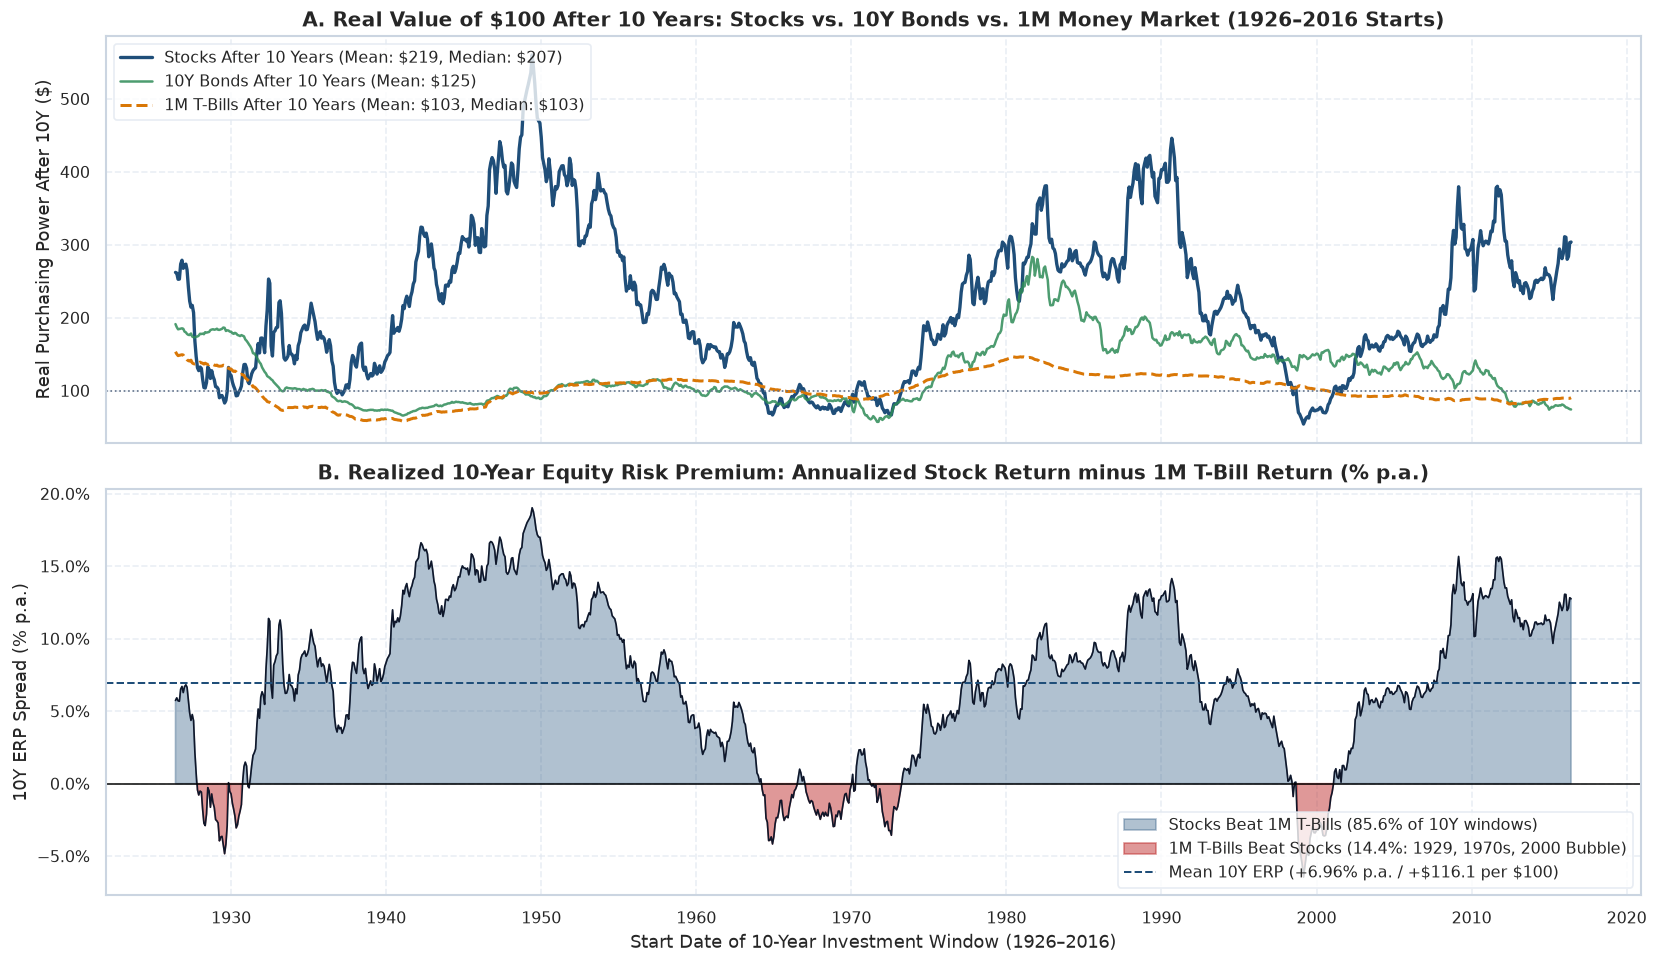

In [15]:
# Figure 08: Equity Risk Premium (ERP) — 10-Year Terminal Wealth & Spread of Stocks vs 1M T-Bills
fig, axes = plt.subplots(2, 1, figsize=(14, 8.2), sharex=True)

ax = axes[0]
ax.plot(comp10.index, comp10["stock_wealth_100"], color=eu.PALETTE["Stocks"], lw=2.0, label=f"Stocks After 10 Years (Mean: \${comp10['stock_wealth_100'].mean():.0f}, Median: \${comp10['stock_wealth_100'].median():.0f})")
ax.plot(comp10.index, comp10["bond10y_wealth_100"], color=eu.PALETTE["10Y Gov Bonds"], lw=1.5, alpha=0.85, label=f"10Y Bonds After 10 Years (Mean: \${comp10['bond10y_wealth_100'].mean():.0f})")
ax.plot(comp10.index, comp10["tbill1m_wealth_100"], color=eu.PALETTE["1M T-Bills"], lw=1.8, ls="--", label=f"1M T-Bills After 10 Years (Mean: \${comp10['tbill1m_wealth_100'].mean():.0f}, Median: \${comp10['tbill1m_wealth_100'].median():.0f})")
ax.axhline(100, color="#64748b", ls=":", lw=1.0)
ax.set_title("A. Real Value of $100 After 10 Years: Stocks vs. 10Y Bonds vs. 1M Money Market (1926–2016 Starts)")
ax.set_ylabel("Real Purchasing Power After 10Y ($)")
ax.legend(loc="upper left")

ax2 = axes[1]
erp_pct = comp10["erp_pa"] * 100
ax2.fill_between(erp_pct.index, erp_pct, 0, where=(erp_pct >= 0), color=eu.PALETTE["Stocks"], alpha=0.35, label="Stocks Beat 1M T-Bills (85.6% of 10Y windows)")
ax2.fill_between(erp_pct.index, erp_pct, 0, where=(erp_pct < 0), color=eu.PALETTE["Inflation"], alpha=0.45, label="1M T-Bills Beat Stocks (14.4%: 1929, 1970s, 2000 Bubble)")
ax2.plot(erp_pct.index, erp_pct, color="#0f172a", lw=1.0)
ax2.axhline(erp_pct.mean(), color=eu.PALETTE["Stocks"], ls="--", lw=1.2, label=f"Mean 10Y ERP (+{erp_pct.mean():.2f}% p.a. / +\$116.1 per \$100)")
ax2.axhline(0, color="black", lw=0.9)
ax2.set_title("B. Realized 10-Year Equity Risk Premium: Annualized Stock Return minus 1M T-Bill Return (% p.a.)")
ax2.set_xlabel("Start Date of 10-Year Investment Window (1926–2016)")
ax2.set_ylabel("10Y ERP Spread (% p.a.)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.legend(loc="lower right")

fig.tight_layout()
eu.save_fig(fig, "08_equity_risk_premium_10y_vs_tbills")
plt.show()

**Equity Risk Premium (ERP) Findings:**
- Over 10-year horizons since 1926, **staying invested in stocks beat rolling 1-month Treasury bills in 85.6% of all windows (925 out of 1,081)**, delivering an average excess return of **+6.96% p.a.** (median **+7.07% p.a.**).
- In real purchasing-power terms, **\$100 invested for 10 years** grew on average to **\$219.16 in stocks** (median **\$207.28**—more than doubling purchasing power!) vs. just **\$103.05 in 1M T-bills** (median **\$102.93**)—an average 10-year wealth advantage of **+\$116.11 per \$100 invested**!
- Crucially for our **Research Goal**, the **14.4% of 10-year windows where stocks lost to cash** were **not random**: they occurred almost exclusively when investors bought at **extreme valuation peaks** (1929, late 1960s, and 1998–2001 Dot-Com peak where 10Y ERP dropped to `-6.44%` p.a.)! This directly motivates testing valuation-based forecasting models in Section 4.

---
## 4. Multivariate Non-Graphical & Graphical EDA

### 4.1 Asset Correlations with Inflation & "Are Stocks Negatively Correlated to Bonds?"
We examine two central bivariate/multivariate portfolio questions:
1. **How do 1M Treasury bills, 10Y government bonds, and stocks correlate with inflation**—both in **nominal** and **real** rolling 1-year terms?
2. **Are stocks negatively correlated to bonds?** Or is negative stock–bond correlation a regime-dependent phenomenon (*Lecture `DEA-04` Slide 54: Subgroup / Aggregation Confounding*)?

In [16]:
# Compute rolling 1-year Nominal and Real returns for correlation analysis (matched 1927-06 to 2026-06)
r1y_df = pd.DataFrame({
    "Inflation (1Y)": df["inf_1y"],
    "1M T-Bill (Nom)": df["tbill1m_tr_nom"] / df["tbill1m_tr_nom"].shift(12) - 1,
    "10Y Bond (Nom)": df["bond10y_tr_nom"] / df["bond10y_tr_nom"].shift(12) - 1,
    "Stocks (Nom)": df["tr_index_nom"] / df["tr_index_nom"].shift(12) - 1,
    "1M T-Bill (Real)": df["tbill1m_tr_real"] / df["tbill1m_tr_real"].shift(12) - 1,
    "10Y Bond (Real)": df["bond10y_tr_real"] / df["bond10y_tr_real"].shift(12) - 1,
    "Stocks (Real)": df["tr_index"] / df["tr_index"].shift(12) - 1,
}).dropna()

corr_nom = r1y_df[["Inflation (1Y)", "1M T-Bill (Nom)", "10Y Bond (Nom)", "Stocks (Nom)"]].corr()
corr_real = r1y_df[["Inflation (1Y)", "1M T-Bill (Real)", "10Y Bond (Real)", "Stocks (Real)"]].corr()

# Stock-Bond monthly correlation overall and by macroeconomic era
sb_eras = []
for label, sl in [
    ("Full Sample (1871–2026)", slice("1871-01-01", "2026-06-01")),
    ("1. Pre-1926 (1871–1925)", slice("1871-01-01", "1925-12-01")),
    ("2a. Early Modern / WWII Peg (1926–1965)", slice("1926-01-01", "1965-12-01")),
    ("2b. Great Inflation & Volcker Era (1966–1999)", slice("1966-01-01", "1999-12-01")),
    ("3. Low-Inflation 'Flight-to-Safety' Era (2000–2020)", slice("2000-01-01", "2020-12-01")),
    ("4. Post-COVID Inflation Reset (2021–2026)", slice("2021-01-01", "2026-06-01")),
]:
    sub = df.loc[sl]
    sb_eras.append({
        "era": label,
        "months": int(sub["ret_real"].notna().sum()),
        "mean_1y_inflation_pct": round(float(sub["inf_1y"].mean() * 100), 2),
        "stock_bond_corr_nominal": round(float(sub["ret_nom"].corr(sub["ret_bond10y_nom"])), 3),
        "stock_bond_corr_real": round(float(sub["ret_real"].corr(sub["ret_bond10y_real"])), 3),
    })

sb_era_df = pd.DataFrame(sb_eras)
eu.save_table(corr_real, "07a_inflation_asset_corr_1y_real", title="1-Year Rolling Real Return & Inflation Correlation Matrix (1927–2026)", float_fmt="{:.3f}")
eu.save_table(corr_nom, "07b_inflation_asset_corr_1y_nominal", title="1-Year Rolling Nominal Return & Inflation Correlation Matrix (1927–2026)", float_fmt="{:.3f}")
eu.save_table(sb_era_df, "07c_stock_bond_correlation_by_era", title="Monthly Stock–10Y Bond Correlation Across Inflation Regimes", float_fmt="{:.3f}", index=False)

display(sb_era_df)

,era,months,mean_1y_inflation_pct,stock_bond_corr_nominal,stock_bond_corr_real
0,Full Sample (1871–2026),1865,2.30,0.037,0.133
1,1. Pre-1926 (1871–1925),659,0.96,0.060,0.300
2,2a. Early Modern / WWII Peg (1926–1965),480,1.59,-0.045,0.006
3,2b. Great Inflation & Volcker Era (1966–1999),408,5.06,0.282,0.322
4,3. Low-Inflation 'Flight-to-Safety' Era (2000–...,252,2.13,-0.329,-0.295
5,4. Post-COVID Inflation Reset (2021–2026),66,4.39,0.311,0.376


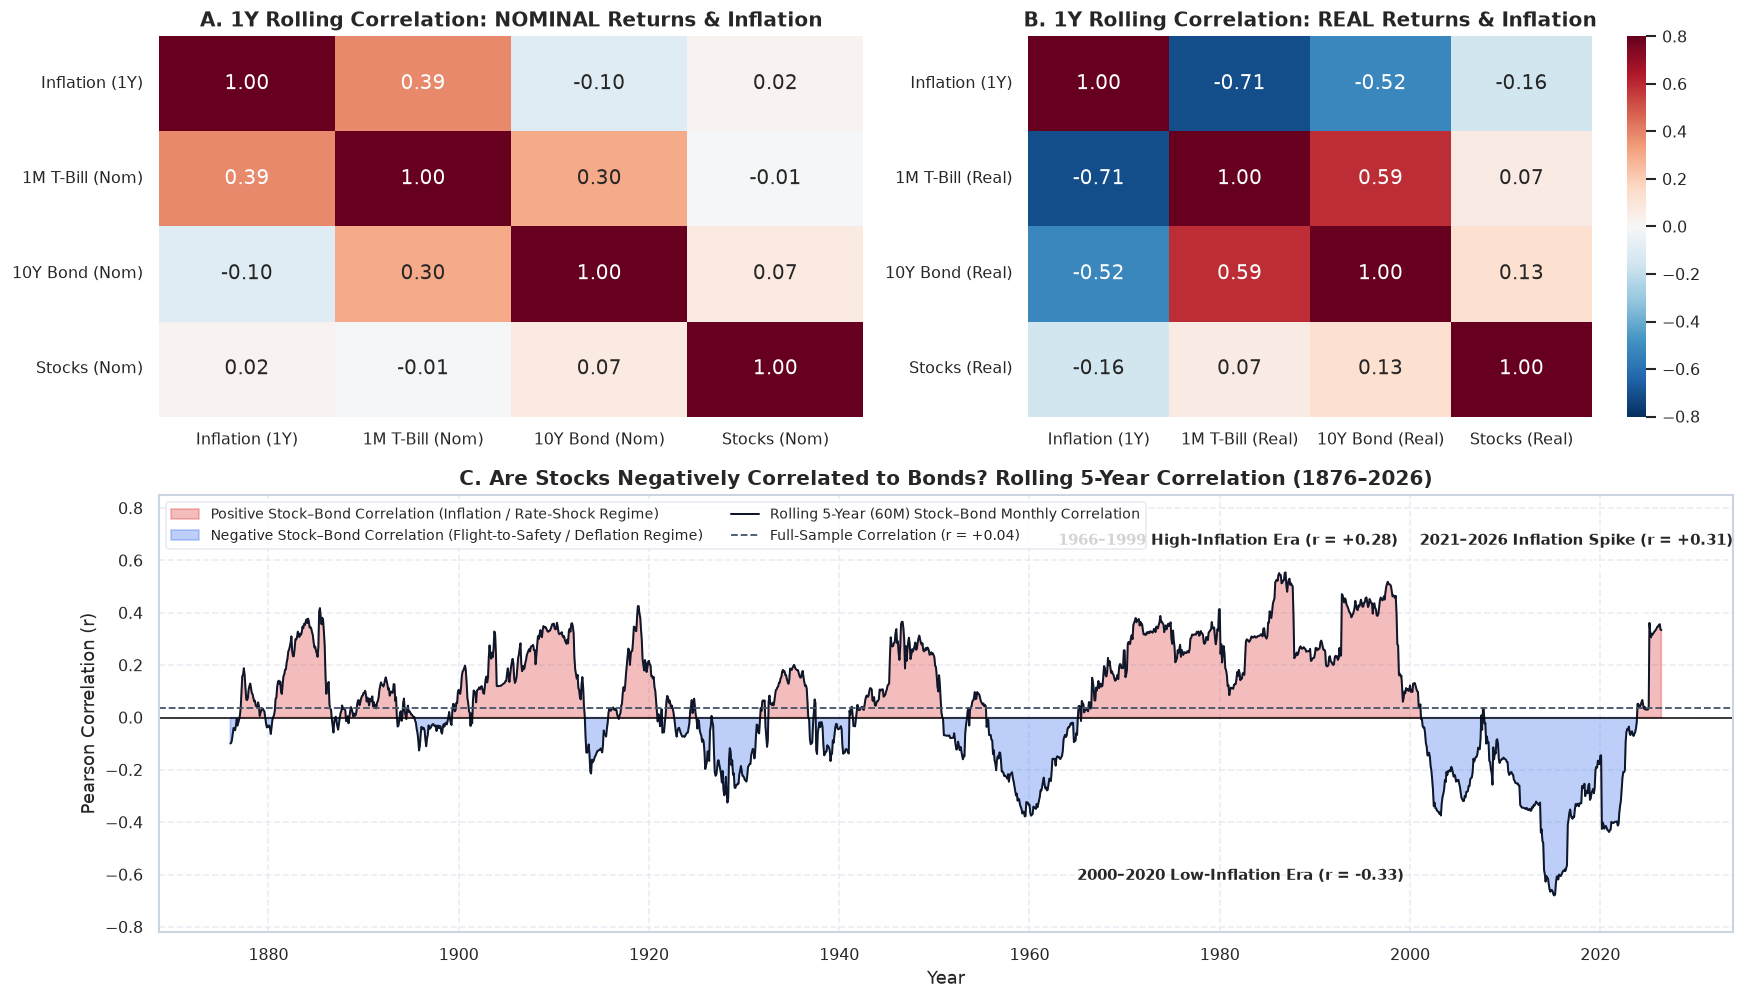

In [17]:
# Figure 09: Inflation Correlations (Nominal vs Real) & Rolling 5-Year Stock-Bond Correlation Across Regimes
fig = plt.figure(figsize=(15, 8.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15])

ax1 = fig.add_subplot(gs[0, 0])
sns.heatmap(corr_nom, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-0.8, vmax=0.8, center=0, ax=ax1, cbar=False)
ax1.set_title("A. 1Y Rolling Correlation: NOMINAL Returns & Inflation")

ax2 = fig.add_subplot(gs[0, 1])
sns.heatmap(corr_real, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-0.8, vmax=0.8, center=0, ax=ax2)
ax2.set_title("B. 1Y Rolling Correlation: REAL Returns & Inflation")

ax3 = fig.add_subplot(gs[1, :])
roll_sb_corr = df["ret_nom"].rolling(60).corr(df["ret_bond10y_nom"])
ax3.fill_between(roll_sb_corr.index, roll_sb_corr, 0, where=(roll_sb_corr >= 0), color="#dc2626", alpha=0.30, label="Positive Stock–Bond Correlation (Inflation / Rate-Shock Regime)")
ax3.fill_between(roll_sb_corr.index, roll_sb_corr, 0, where=(roll_sb_corr < 0), color="#2563eb", alpha=0.30, label="Negative Stock–Bond Correlation (Flight-to-Safety / Deflation Regime)")
ax3.plot(roll_sb_corr.index, roll_sb_corr, color="#0f172a", lw=1.2, label="Rolling 5-Year (60M) Stock–Bond Monthly Correlation")
ax3.axhline(0, color="black", lw=0.9)
ax3.axhline(df["ret_nom"].corr(df["ret_bond10y_nom"]), color="#475569", ls="--", lw=1.1, label=f"Full-Sample Correlation (r = +{df['ret_nom'].corr(df['ret_bond10y_nom']):.2f})")
ax3.annotate("1966–1999 High-Inflation Era (r = +0.28)", xy=(pd.Timestamp("1986-01-01"), 0.50), xytext=(pd.Timestamp("1963-01-01"), 0.66), arrowprops=dict(arrowstyle="->"), fontsize=9, fontweight="bold")
ax3.annotate("2000–2020 Low-Inflation Era (r = -0.33)", xy=(pd.Timestamp("2012-01-01"), -0.48), xytext=(pd.Timestamp("1965-01-01"), -0.62), arrowprops=dict(arrowstyle="->"), fontsize=9, fontweight="bold")
ax3.annotate("2021–2026 Inflation Spike (r = +0.31)", xy=(pd.Timestamp("2025-01-01"), 0.36), xytext=(pd.Timestamp("2001-01-01"), 0.66), arrowprops=dict(arrowstyle="->"), fontsize=9, fontweight="bold")
ax3.set_title("C. Are Stocks Negatively Correlated to Bonds? Rolling 5-Year Correlation (1876–2026)")
ax3.set_ylabel("Pearson Correlation (r)")
ax3.set_xlabel("Year")
ax3.set_ylim(-0.82, 0.85)
ax3.legend(loc="upper left", ncol=2, fontsize=8.4)

fig.tight_layout()
eu.save_fig(fig, "09_inflation_and_stock_bond_correlations")
plt.show()

**Answers to Our Two Correlation Questions:**
1. **Correlation with Inflation (1M T-Bills vs. 10Y Bonds vs. Stocks):**
   - **Nominally (Panel A):** 1M T-bill yields adjust upward with Federal Reserve hikes, giving a **positive correlation with 1Y inflation (`r = +0.39`)**, whereas 10Y bonds suffer immediate duration price losses (`r = -0.10`), and nominal stocks are roughly uncorrelated (`r = +0.02`).
   - **In Real Purchasing-Power Terms (Panel B):** Central bank rate hikes historically lagged behind inflation surges! Consequently, **real 1M T-bill returns have a strong negative correlation with inflation (`r = -0.71`)**, and **real 10Y bond returns correlate at `r = -0.53`**, whereas **real stock returns are far less damaged (`r = -0.16` at 1Y)** because corporate revenues and dividends adjust upward with consumer prices over time.
2. **Are Stocks Negatively Correlated to Bonds? — No Unconditionally, It Depends on Inflation!**
   - Across the full 155-year sample, monthly stock–bond correlation is slightly **positive** (`r = +0.037` nominal, `r = +0.133` real).
   - **Subgroup Regime Effect:** The widespread belief that "bonds always hedge stock crashes" stems from the **2000–2020 low-inflation era (`r = -0.329`)**, when demand recessions triggered rate cuts that rallied bonds. Whenever **inflation shocks** dominate (**1966–1999: `r = +0.282`**; **2021–2026: `r = +0.311`**), rising yields crush stocks and bonds *simultaneously*!

---
### 4.2 Valuation Predictability: Current `P/E` & `CAPE` vs. Next 10-Year Returns & Optimal Forecast Horizon
Now we test the core long-horizon pillar of our research question:
- How strongly do **current `P/E`** and **current `CAPE`** predict the **next 10 years of real stock returns**?
- **Across which time horizons ($h = 1, 2, \dots, 20$ years) do `P/E` and `CAPE` have the greatest relevance?**

In [18]:
# Scan horizons 1..20 years for P/E, Earnings Yield (1/PE), CAPE, and CAPE Yield (1/CAPE)
val_scan_all = eu.valuation_horizon_scan(df, horizons=range(1, 21), start_date=None)
val_scan_1926 = eu.valuation_horizon_scan(df, horizons=range(1, 21), start_date="1926-06-01")
val_scan_all["cape_r2_post1926"] = val_scan_1926["cape_r2"]
val_scan_all["earnings_yield_r2_post1926"] = val_scan_1926["earnings_yield_r2"]

eu.save_table(val_scan_all, "08_valuation_horizon_relevance_1_to_20y", title="Valuation Predictability (R2 and Correlations) Across 1-to-20 Year Forecast Horizons", float_fmt="{:.4f}", index=False)

best_cape_row = val_scan_all.loc[val_scan_all["cape_r2"].idxmax()]
best_ey_row = val_scan_all.loc[val_scan_all["earnings_yield_r2"].idxmax()]
print(f"Peak CAPE linear R² (full sample): {best_cape_row['cape_r2']:.1%} at horizon = {int(best_cape_row['horizon_years'])} years (post-1926 peak = {val_scan_1926['cape_r2'].max():.1%} at {int(val_scan_1926.loc[val_scan_1926['cape_r2'].idxmax(), 'horizon_years'])}Y)")
print(f"At 10Y horizon -> Raw P/E linear R² = {val_scan_all.loc[9, 'pe_r2']:.1%}, Spearman rho² = {val_scan_all.loc[9, 'pe_spearman_rho2']:.1%}, Earnings Yield (1/PE) linear R² = {val_scan_all.loc[9, 'earnings_yield_r2']:.1%}, CAPE linear R² = {val_scan_all.loc[9, 'cape_r2']:.1%}")
display(val_scan_all[val_scan_all["horizon_years"].isin([1, 3, 5, 7, 10, 12, 15, 18, 20])].round(3))

Peak CAPE linear R² (full sample): 33.1% at horizon = 19 years (post-1926 peak = 39.5% at 13Y)
At 10Y horizon -> Raw P/E linear R² = 4.5%, Spearman rho² = 19.9%, Earnings Yield (1/PE) linear R² = 22.9%, CAPE linear R² = 23.4%


,horizon_years,n_pe,pe_pearson_r,pe_r2,pe_spearman_rho,pe_spearman_rho2,earnings_yield_r2,n_cape,cape_pearson_r,cape_r2,cape_spearman_rho,cape_spearman_rho2,cape_yield_r2,cape_r2_post1926,earnings_yield_r2_post1926
0,1,1851,-0.069,0.005,-0.134,0.018,0.016,1732,-0.172,0.030,-0.162,0.026,0.044,0.039,0.035
2,3,1827,-0.108,0.012,-0.191,0.036,0.037,1708,-0.282,0.080,-0.241,0.058,0.082,0.102,0.077
4,5,1803,-0.093,0.009,-0.248,0.061,0.072,1684,-0.344,0.118,-0.311,0.097,0.152,0.136,0.104
6,7,1779,-0.140,0.019,-0.305,0.093,0.105,1660,-0.362,0.131,-0.336,0.113,0.201,0.166,0.183
9,10,1743,-0.213,0.045,-0.446,0.199,0.229,1624,-0.484,0.234,-0.451,0.204,0.254,0.305,0.263
11,12,1719,-0.185,0.034,-0.489,0.239,0.252,1600,-0.549,0.302,-0.565,0.320,0.273,0.376,0.277
14,15,1683,-0.180,0.032,-0.488,0.238,0.216,1564,-0.570,0.325,-0.639,0.408,0.343,0.382,0.363
17,18,1647,-0.454,0.206,-0.547,0.300,0.321,1528,-0.574,0.330,-0.667,0.445,0.380,0.384,0.466
19,20,1623,-0.443,0.196,-0.558,0.311,0.315,1504,-0.565,0.319,-0.688,0.474,0.348,0.368,0.406


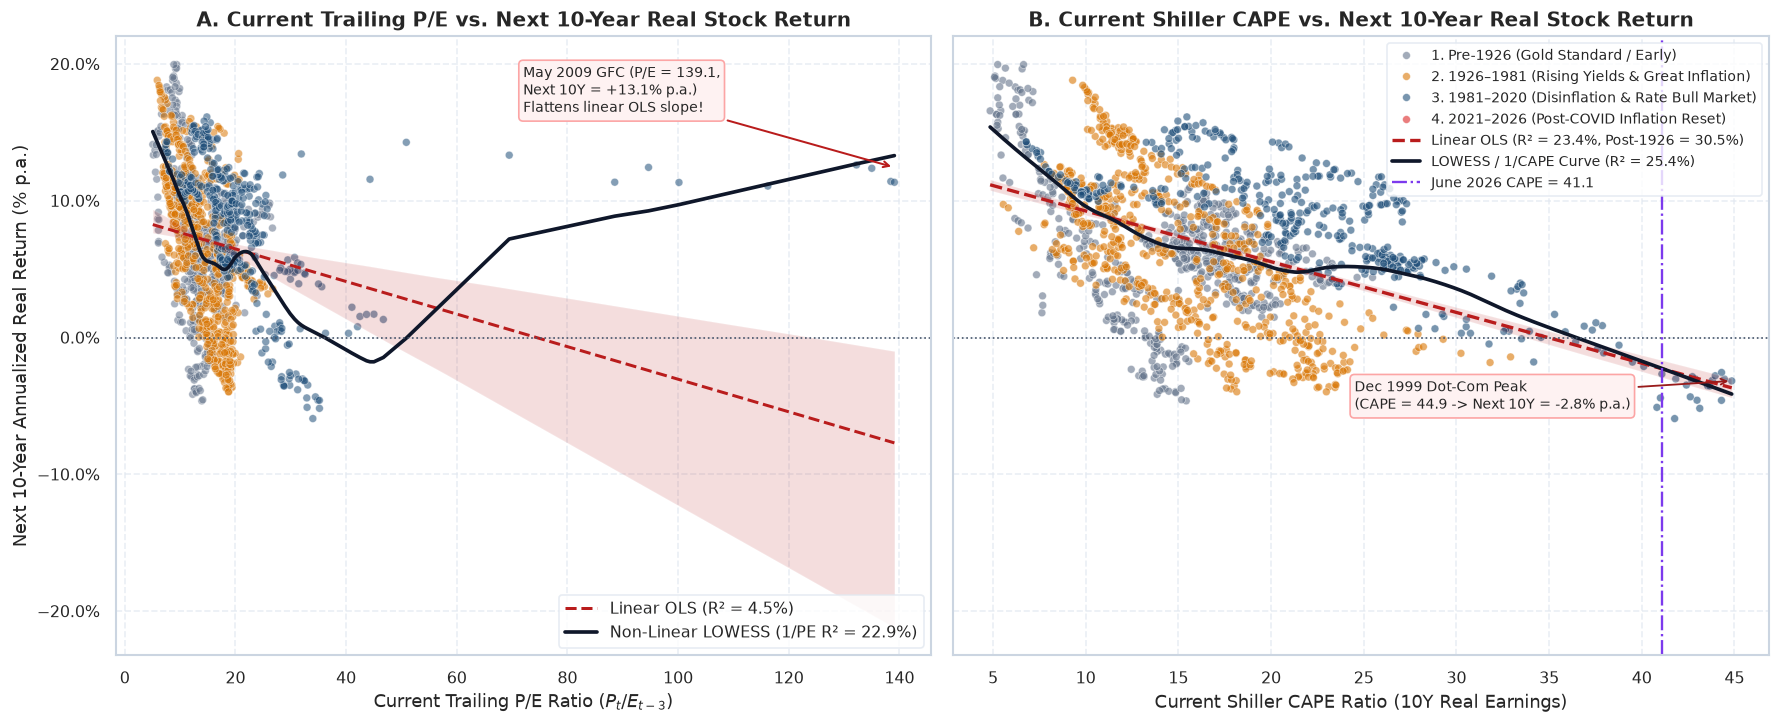

In [19]:
# Figure 10: Scatterplots of Current P/E vs Next 10Y Returns AND Current CAPE vs Next 10Y Returns
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), sharey=True)

era_colors = {
    "1. Pre-1926 (Gold Standard / Early)": "#64748b",
    "2. 1926–1981 (Rising Yields & Great Inflation)": "#d97706",
    "3. 1981–2020 (Disinflation & Rate Bull Market)": "#1f4e79",
    "4. 2021–2026 (Post-COVID Inflation Reset)": "#dc2626",
}

# Left: Raw P/E vs Next 10Y Real Return
ax = axes[0]
sub_pe = df[["pe", "fwd_ret_10y", "era"]].dropna().copy()
sub_pe["fwd_pct"] = sub_pe["fwd_ret_10y"] * 100
sns.scatterplot(data=sub_pe, x="pe", y="fwd_pct", hue="era", palette=era_colors, alpha=0.55, s=22, ax=ax, legend=False)
sns.regplot(data=sub_pe, x="pe", y="fwd_pct", scatter=False, ax=ax, color="#b91c1c", line_kws={"lw": 1.8, "ls": "--"})
ax.plot([], [], color="#b91c1c", lw=1.8, ls="--", label=f"Linear OLS (R² = {val_scan_all.loc[9, 'pe_r2']:.1%})")
lowess_pe = sm.nonparametric.lowess(sub_pe["fwd_pct"], sub_pe["pe"], frac=0.35)
ax.plot(lowess_pe[:, 0], lowess_pe[:, 1], color="#0f172a", lw=2.2, label=f"Non-Linear LOWESS (1/PE R² = {val_scan_all.loc[9, 'earnings_yield_r2']:.1%})")
ax.axhline(0, color="#475569", ls=":", lw=1)
ax.annotate(
    "May 2009 GFC (P/E = 139.1,\nNext 10Y = +13.1% p.a.)\nFlattens linear OLS slope!",
    xy=(139.09, sub_pe.loc["2009-05-01", "fwd_pct"]),
    xytext=(72, 16.5),
    arrowprops=dict(arrowstyle="->", color="#b91c1c", lw=1.2),
    fontsize=8.7,
    bbox=dict(boxstyle="round,pad=0.3", fc="#fef2f2", ec="#fca5a5"),
)
ax.set_title("A. Current Trailing P/E vs. Next 10-Year Real Stock Return")
ax.set_xlabel("Current Trailing P/E Ratio ($P_t / E_{t-3}$)")
ax.set_ylabel("Next 10-Year Annualized Real Return (% p.a.)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc="lower right")

# Right: Shiller CAPE vs Next 10Y Real Return
ax2 = axes[1]
sub_ca = df[["cape", "fwd_ret_10y", "era"]].dropna().copy()
sub_ca["fwd_pct"] = sub_ca["fwd_ret_10y"] * 100
sns.scatterplot(data=sub_ca, x="cape", y="fwd_pct", hue="era", palette=era_colors, alpha=0.6, s=22, ax=ax2)
sns.regplot(data=sub_ca, x="cape", y="fwd_pct", scatter=False, ax=ax2, color="#b91c1c", line_kws={"lw": 2.0, "ls": "--"})
ax2.plot([], [], color="#b91c1c", lw=2.0, ls="--", label=f"Linear OLS (R² = {val_scan_all.loc[9, 'cape_r2']:.1%}, Post-1926 = {val_scan_1926.loc[9, 'cape_r2']:.1%})")
lowess_ca = sm.nonparametric.lowess(sub_ca["fwd_pct"], sub_ca["cape"], frac=0.4)
ax2.plot(lowess_ca[:, 0], lowess_ca[:, 1], color="#0f172a", lw=2.2, label=f"LOWESS / 1/CAPE Curve (R² = {val_scan_all.loc[9, 'cape_yield_r2']:.1%})")
ax2.axhline(0, color="#475569", ls=":", lw=1)
ax2.axvline(df["cape"].iloc[-1], color="#7c3aed", ls="-.", lw=1.4, label=f"June 2026 CAPE = {df['cape'].iloc[-1]:.1f}")
ax2.annotate(
    "Dec 1999 Dot-Com Peak\n(CAPE = 44.9 -> Next 10Y = -2.8% p.a.)",
    xy=(sub_ca.loc["1999-12-01", "cape"], sub_ca.loc["1999-12-01", "fwd_pct"]),
    xytext=(24.5, -5.2),
    arrowprops=dict(arrowstyle="->", color="#991b1b", lw=1.1),
    fontsize=8.7,
    bbox=dict(boxstyle="round,pad=0.3", fc="#fef2f2", ec="#fca5a5"),
)
ax2.set_title("B. Current Shiller CAPE vs. Next 10-Year Real Stock Return")
ax2.set_xlabel("Current Shiller CAPE Ratio (10Y Real Earnings)")
ax2.legend(loc="upper right", fontsize=8.3)

fig.tight_layout()
eu.save_fig(fig, "10_pe_and_cape_vs_10y_returns_scatter")
plt.show()

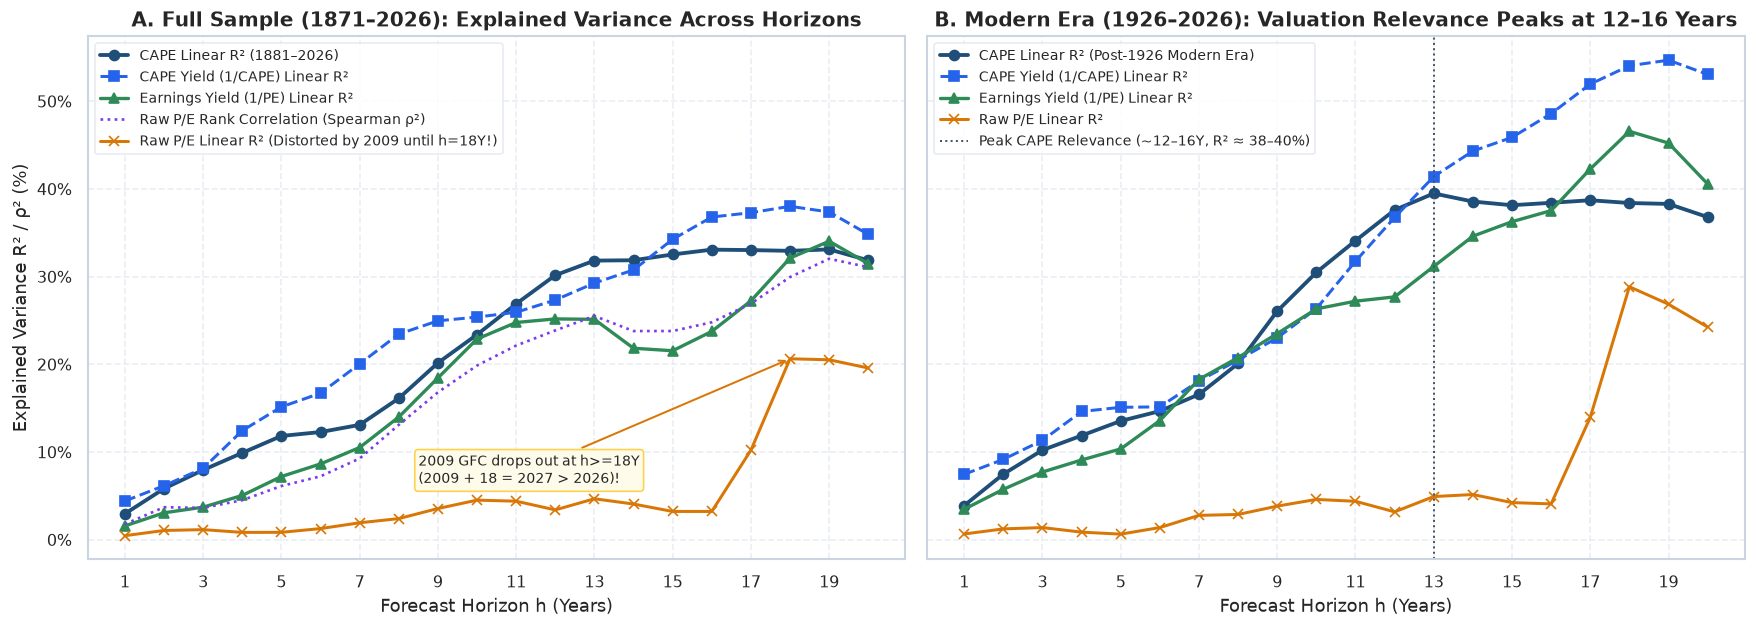

In [20]:
# Figure 11: Horizon Relevance Curve — Across Which Time Horizons Do P/E and CAPE Matter Most?
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.4), sharey=True)

ax = axes[0]
ax.plot(val_scan_all["horizon_years"], val_scan_all["cape_r2"] * 100, marker="o", lw=2.3, color=eu.PALETTE["Stocks"], label="CAPE Linear R² (1881–2026)")
ax.plot(val_scan_all["horizon_years"], val_scan_all["cape_yield_r2"] * 100, marker="s", lw=1.8, ls="--", color="#2563eb", label="CAPE Yield (1/CAPE) Linear R²")
ax.plot(val_scan_all["horizon_years"], val_scan_all["earnings_yield_r2"] * 100, marker="^", lw=2.0, color=eu.PALETTE["10Y Gov Bonds"], label="Earnings Yield (1/PE) Linear R²")
ax.plot(val_scan_all["horizon_years"], val_scan_all["pe_spearman_rho2"] * 100, lw=1.6, ls=":", color="#7c3aed", label="Raw P/E Rank Correlation (Spearman ρ²)")
ax.plot(val_scan_all["horizon_years"], val_scan_all["pe_r2"] * 100, marker="x", lw=1.8, color=eu.PALETTE["1M T-Bills"], label="Raw P/E Linear R² (Distorted by 2009 until h=18Y!)")
ax.annotate(
    "2009 GFC drops out at h>=18Y\n(2009 + 18 = 2027 > 2026)!",
    xy=(18, val_scan_all.loc[17, "pe_r2"] * 100),
    xytext=(8.5, 6.5),
    arrowprops=dict(arrowstyle="->", color=eu.PALETTE["1M T-Bills"], lw=1.2),
    fontsize=8.6,
    bbox=dict(boxstyle="round,pad=0.25", fc="#fffbeb", ec="#fcd34d"),
)
ax.set_title("A. Full Sample (1871–2026): Explained Variance Across Horizons")
ax.set_xlabel("Forecast Horizon h (Years)")
ax.set_ylabel("Explained Variance R² / ρ² (%)")
ax.set_xticks(range(1, 21, 2))
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc="upper left", fontsize=8.4)

ax2 = axes[1]
ax2.plot(val_scan_1926["horizon_years"], val_scan_1926["cape_r2"] * 100, marker="o", lw=2.3, color=eu.PALETTE["Stocks"], label="CAPE Linear R² (Post-1926 Modern Era)")
ax2.plot(val_scan_1926["horizon_years"], val_scan_1926["cape_yield_r2"] * 100, marker="s", lw=1.8, ls="--", color="#2563eb", label="CAPE Yield (1/CAPE) Linear R²")
ax2.plot(val_scan_1926["horizon_years"], val_scan_1926["earnings_yield_r2"] * 100, marker="^", lw=2.0, color=eu.PALETTE["10Y Gov Bonds"], label="Earnings Yield (1/PE) Linear R²")
ax2.plot(val_scan_1926["horizon_years"], val_scan_1926["pe_r2"] * 100, marker="x", lw=1.8, color=eu.PALETTE["1M T-Bills"], label="Raw P/E Linear R²")
ax2.axvline(13, color="#475569", ls=":", lw=1.2, label="Peak CAPE Relevance (~12–16Y, R² ≈ 38–40%)")
ax2.set_title("B. Modern Era (1926–2026): Valuation Relevance Peaks at 12–16 Years")
ax2.set_xlabel("Forecast Horizon h (Years)")
ax2.set_xticks(range(1, 21, 2))
ax2.legend(loc="upper left", fontsize=8.4)

fig.tight_layout()
eu.save_fig(fig, "11_pe_vs_cape_horizon_relevance_r2")
plt.show()

**Major Valuation & Feature-Engineering Discovery (Why Scatterplots Beat Blind Correlation):**
1. **Which Time Horizons Matter Most?** Both `P/E` and `CAPE` have **almost zero predictive power at 1 year** (`R² = 0.5%–3.0%`), gain traction at **5 years** (`CAPE R² = 11.8%`), become **strongly predictive at 10 years** (`CAPE R² = 23.4%` full sample, **`30.5%` post-1926**), and **peak between 12 and 16 years** (`CAPE R² = 33.1%` full sample; **`39.5%` at 13Y post-1926**).
2. **Why Did Raw `P/E` Linear $R^2$ Look Weak (`4.5%`) at 10Y and Suddenly Jump to `20.6%` at 18Y?**  
   Figure 10A and Figure 11A uncover a textbook data-analysis trap: during spring 2009 (`PE = 100–139`), trailing corporate earnings temporarily collapsed near zero, creating extreme right-tail leverage points followed by **+13% p.a.** recovery returns. Those ~6 months flatten linear OLS on raw `pe` for every horizon $h \le 17$ years! At $h = 18$ years (`2009 + 18 = 2027 > 2026`), 2009 drops out of the forward-return sample and linear $R^2$ artificially jumps!
3. **Actionable Fix for Modeling:** Simply inverting `pe` into **Earnings Yield (`1/pe = E_{t-3}/P_t`)** maps near-zero crisis earnings cleanly near `0%` instead of `+∞`, **boosting 10-year linear $R^2$ five-fold from `4.5%` to `22.9%`**—nearly matching `CAPE` (`23.4%`) and `1/CAPE` (`25.4%`)!

---
### 4.3 Multivariate Regime Cross-Tabulation, Feature Matrix & Scatterplot Matrix (`Pairplot`)
Finally, we examine how **all engineered features interact jointly** across 1Y, 5Y, and 10Y targets using cross-tabulation (`pd.crosstab`), grouped statistics, correlation heatmaps, and a multivariate `pairplot`.

In [21]:
# Cross-tabulation of CAPE Valuation Regimes vs 10-Year Outcomes (Positive Real Return & Beating 1M T-Bills)
valid10 = df.dropna(subset=["cape_regime", "fwd_ret_10y"]).copy()
valid10["Positive 10Y Real Return"] = np.where(valid10["fwd_ret_10y"] > 0, "Gain (> 0%)", "Loss (<= 0%)")

ct_counts = pd.crosstab(valid10["cape_regime"], valid10["Positive 10Y Real Return"], margins=True)
ct_pct = pd.crosstab(valid10["cape_regime"], valid10["Positive 10Y Real Return"], normalize="index") * 100

# Combine with category-level summary statistics of 1Y, 5Y, and 10Y returns
cat_stats = df.groupby("cape_regime", observed=True)[["fwd_ret_1y", "fwd_ret_5y", "fwd_ret_10y"]].agg(["count", "mean", "median", "std"])
cat_flat = pd.DataFrame({
    "months_10y": cat_stats[("fwd_ret_10y", "count")],
    "prob_pos_10y_pct": ct_pct.get("Gain (> 0%)", 0.0),
    "mean_1y_pct": cat_stats[("fwd_ret_1y", "mean")] * 100,
    "mean_5y_pct": cat_stats[("fwd_ret_5y", "mean")] * 100,
    "mean_10y_pct": cat_stats[("fwd_ret_10y", "mean")] * 100,
    "median_10y_pct": cat_stats[("fwd_ret_10y", "median")] * 100,
    "std_10y_pct": cat_stats[("fwd_ret_10y", "std")] * 100,
})
eu.save_table(cat_flat, "09_crosstab_cape_regime_vs_returns", title="Cross-Tabulation & Grouped Return Statistics by CAPE Valuation Regime", float_fmt="{:.2f}")

# Full Feature-Target Correlation Table (Pearson & Spearman)
feat_cols = ["pe", "earnings_yield", "cape", "cape_yield", "yield_gap", "GS10", "inf_1y", "mom_6m", "mom_12m", "vol_12m", "drawdown"]
targ_cols = ["fwd_ret_1y", "fwd_ret_5y", "fwd_ret_10y"]
pearson_ft = df[feat_cols + targ_cols].corr().loc[feat_cols, targ_cols].add_prefix("pearson_")
spearman_ft = df[feat_cols + targ_cols].corr(method="spearman").loc[feat_cols, targ_cols].add_prefix("spearman_")
ft_corr_table = pd.concat([pearson_ft, spearman_ft], axis=1)
eu.save_table(ft_corr_table, "10_feature_target_correlations", title="Feature-to-Target Pearson and Spearman Correlations Across Horizons", float_fmt="{:.3f}")

display(cat_flat.round(2))
display(ft_corr_table.round(3))

,months_10y,prob_pos_10y_pct,mean_1y_pct,mean_5y_pct,mean_10y_pct,median_10y_pct,std_10y_pct
cape_regime,,,,,,,
Cheap (CAPE < 12),422,100.00,14.37,11.17,10.33,10.43,4.35
Fair (12 <= CAPE < 18),603,87.40,8.52,6.20,6.49,6.54,4.92
Expensive (18 <= CAPE < 25),424,81.60,3.63,6.00,4.74,4.94,4.42
Bubble / Very Expensive (CAPE >= 25),175,77.71,6.77,3.15,3.60,4.92,4.32


,pearson_fwd_ret_1y,pearson_fwd_ret_5y,pearson_fwd_ret_10y,spearman_fwd_ret_1y,spearman_fwd_ret_5y,spearman_fwd_ret_10y
pe,-0.069,-0.093,-0.213,-0.134,-0.248,-0.446
earnings_yield,0.126,0.269,0.479,0.134,0.248,0.446
cape,-0.172,-0.344,-0.484,-0.162,-0.311,-0.451
cape_yield,0.210,0.389,0.504,0.162,0.311,0.451
yield_gap,0.127,0.212,0.345,0.139,0.210,0.302
GS10,-0.026,0.023,0.077,-0.080,-0.113,-0.069
inf_1y,-0.158,-0.131,0.160,-0.168,-0.133,0.127
mom_6m,0.036,-0.081,-0.049,0.082,-0.064,-0.027
mom_12m,-0.072,-0.143,-0.090,-0.035,-0.122,-0.070
vol_12m,0.093,0.052,-0.039,0.062,0.059,-0.006


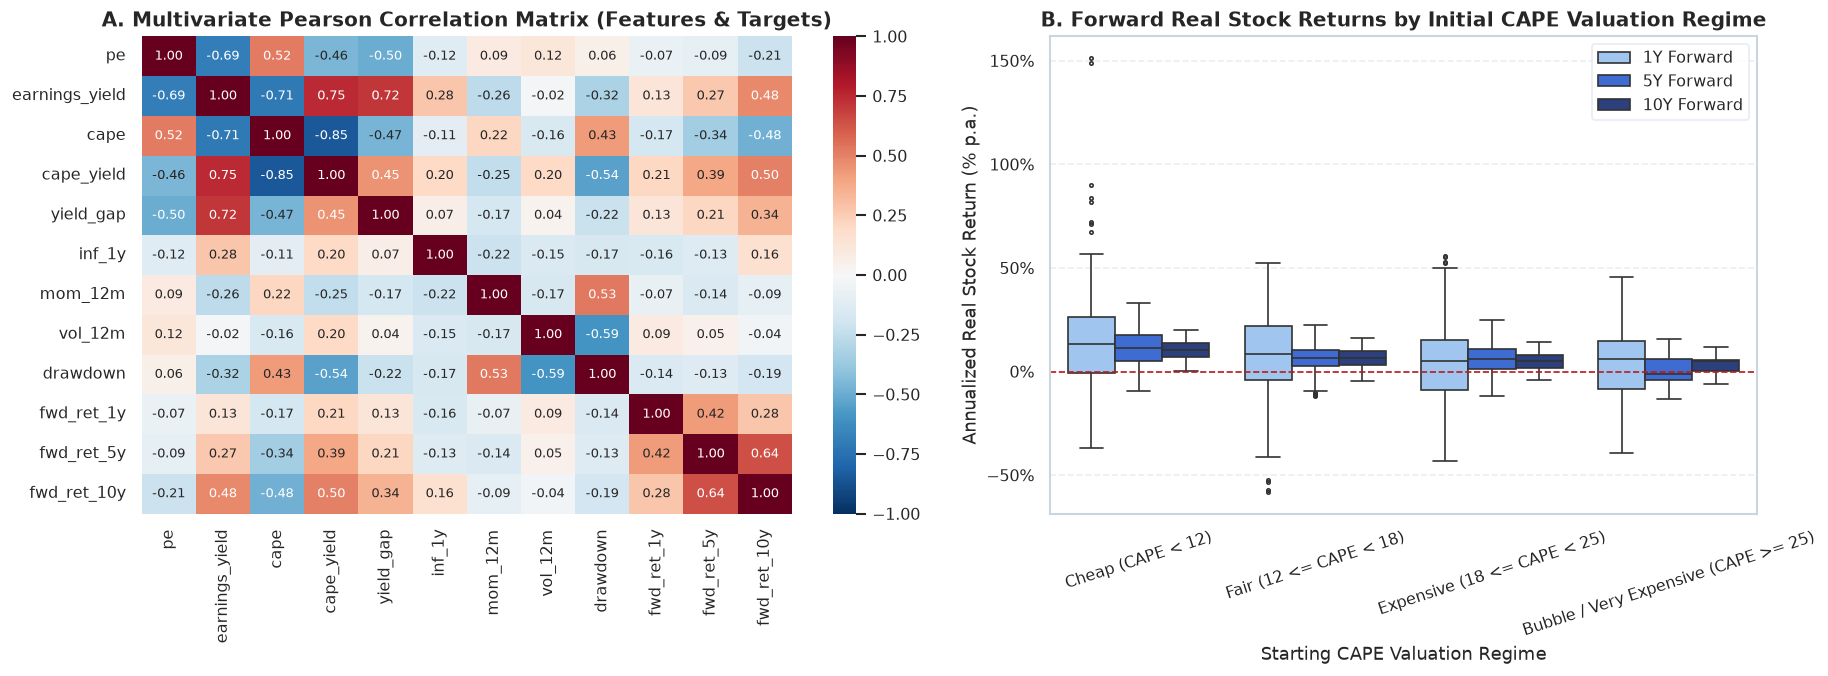

In [22]:
# Figure 12: Multivariate Feature-Target Heatmap & Grouped Boxplots Across CAPE Valuation Regimes
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8), gridspec_kw={"width_ratios": [1.15, 1]})

ax = axes[0]
heat_cols = ["pe", "earnings_yield", "cape", "cape_yield", "yield_gap", "inf_1y", "mom_12m", "vol_12m", "drawdown", "fwd_ret_1y", "fwd_ret_5y", "fwd_ret_10y"]
sns.heatmap(df[heat_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax, annot_kws={"size": 7.8})
ax.set_title("A. Multivariate Pearson Correlation Matrix (Features & Targets)")

ax2 = axes[1]
long_cape = valid10[["cape_regime", "fwd_ret_1y", "fwd_ret_5y", "fwd_ret_10y"]].melt(
    id_vars="cape_regime", var_name="Horizon", value_name="Return"
)
long_cape["Return"] = long_cape["Return"] * 100
long_cape["Horizon"] = long_cape["Horizon"].map({"fwd_ret_1y": "1Y Forward", "fwd_ret_5y": "5Y Forward", "fwd_ret_10y": "10Y Forward"})
sns.boxplot(data=long_cape, x="cape_regime", y="Return", hue="Horizon", palette=["#93c5fd", "#2563eb", "#1e3a8a"], ax=ax2, fliersize=2)
ax2.axhline(0, color="#b91c1c", ls="--", lw=1)
ax2.set_title("B. Forward Real Stock Returns by Initial CAPE Valuation Regime")
ax2.set_xlabel("Starting CAPE Valuation Regime")
ax2.set_ylabel("Annualized Real Stock Return (% p.a.)")
ax2.tick_params(axis="x", rotation=18)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.legend(loc="upper right")

fig.tight_layout()
eu.save_fig(fig, "12_multivariate_feature_heatmap_and_regimes")
plt.show()

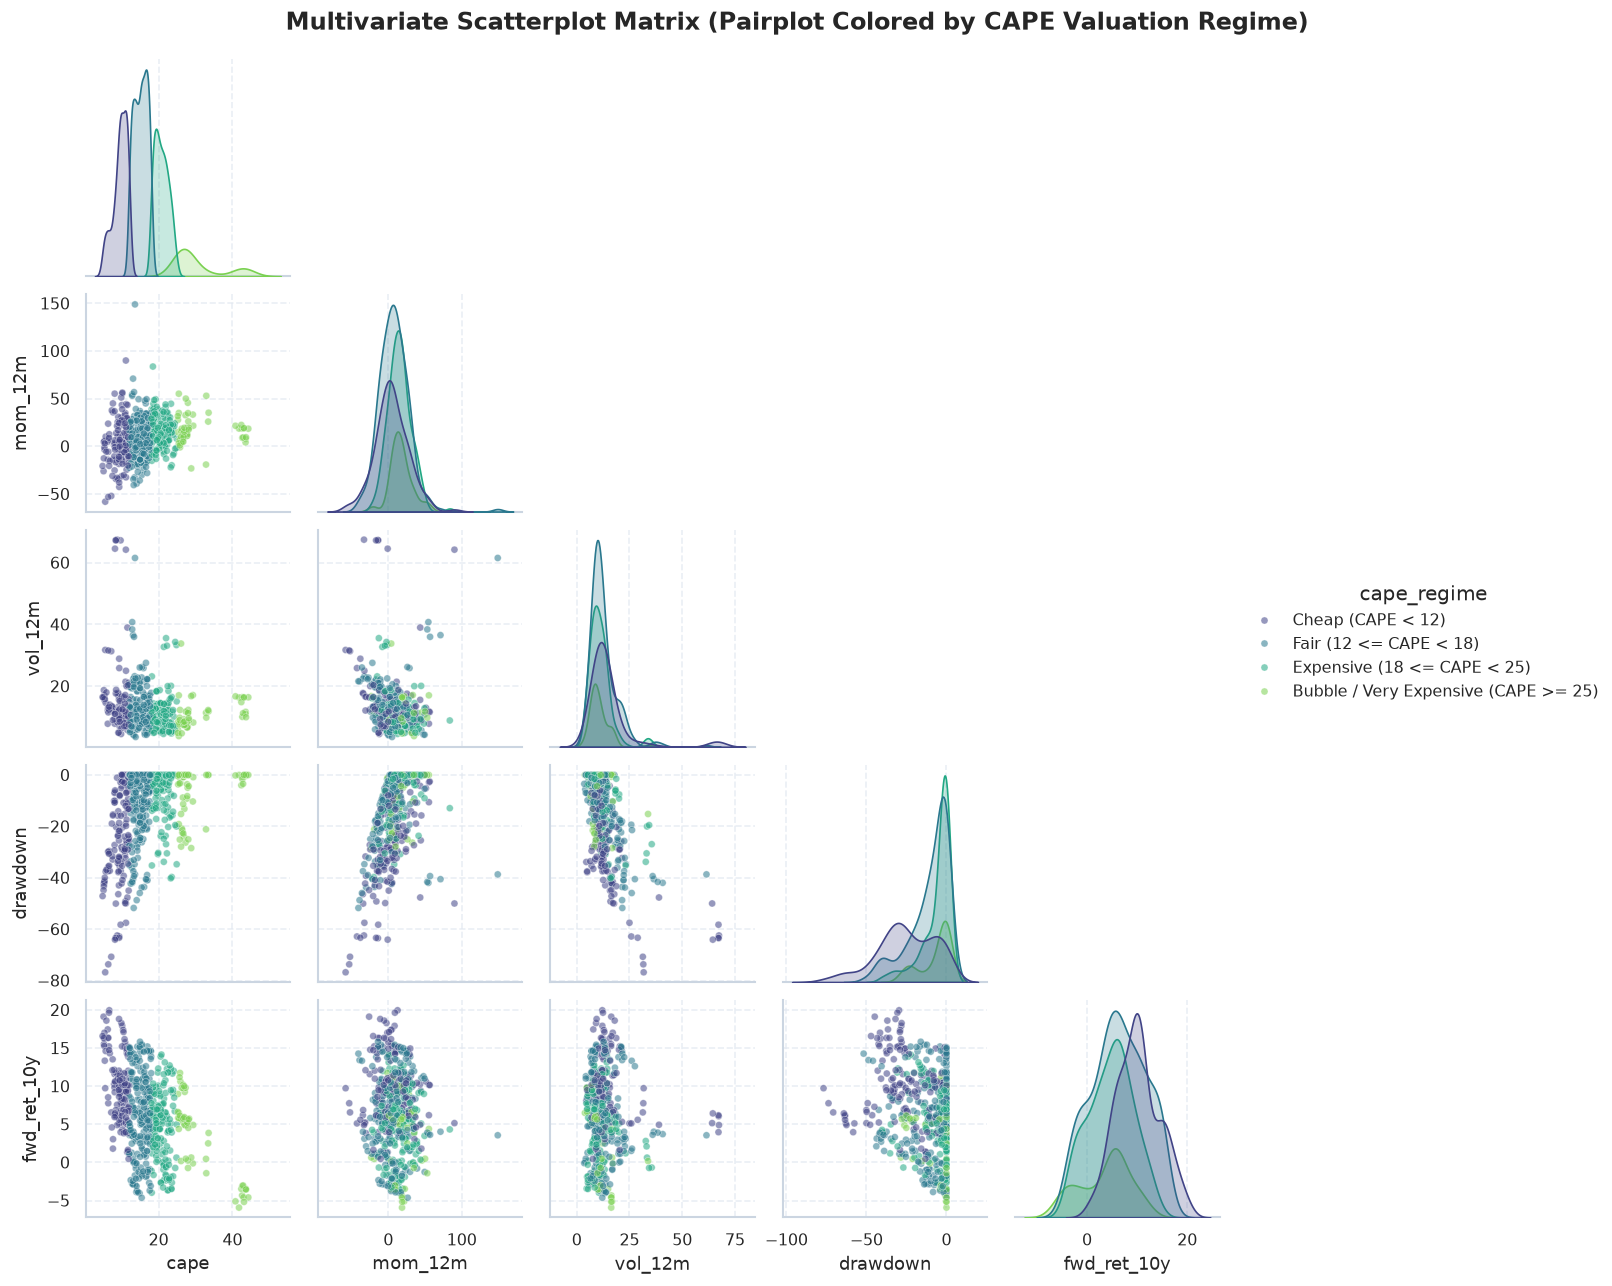

In [23]:
# Figure 13: Multivariate Scatterplot Matrix (Pairplot of Core Signals & 1Y / 10Y Targets)
pair_df = df[["cape", "mom_12m", "vol_12m", "drawdown", "fwd_ret_1y", "fwd_ret_10y", "cape_regime"]].dropna().copy()
for c in ["mom_12m", "vol_12m", "drawdown", "fwd_ret_1y", "fwd_ret_10y"]:
    pair_df[c] = pair_df[c] * 100

g = sns.pairplot(
    pair_df.sample(n=min(600, len(pair_df)), random_state=42),
    vars=["cape", "mom_12m", "vol_12m", "drawdown", "fwd_ret_10y"],
    hue="cape_regime",
    palette="viridis",
    plot_kws={"alpha": 0.55, "s": 18},
    diag_kind="kde",
    corner=True,
    height=2.1,
)
g.figure.suptitle("Multivariate Scatterplot Matrix (Pairplot Colored by CAPE Valuation Regime)", y=1.02, fontweight="bold")
eu.save_fig(g.figure, "13_multivariate_pairplot")
plt.show()

---
## 5. Summary & How EDA Informs Data Processing, Feature Engineering & Modeling (Section 3.2)

### 5.1 Why and How This EDA Contributes to Better Project Results
Without exploratory analysis, feeding raw financial ratios and overlapping multi-year targets into standard machine-learning pipelines would fail for three concrete reasons uncovered above:
1. **Hidden Denominator Outliers Destroy Linear Models (`P/E = 139` in 2009):** A purely mechanical regression on raw `pe` yields $R^2 = 4.5\%$ at 10Y and falsely suggests P/E is irrelevant until 18Y. Graphical inspection (Figures 3B, 10A, 11A) revealed that 6 recession months in 2009 act as extreme leverage points; inverting `pe` to `earnings_yield = 1/pe` immediately restores $R^2 = 22.9\%$.
2. **Horizon-Specific Signal Separation:** At **1 year**, return noise is huge (`std = 19.2%`) and valuation explains $< 4\%$ of variance, while short-term risk/trend indicators (`inf_1y`, `drawdown`, `vol_12m`, `mom_6m`) carry the primary signal. At **5–10+ years**, noise averages out (`10Y std = 5.1%`) and valuation (`cape`, `cape_yield`, `earnings_yield`, `yield_gap`) dominates (`R² = 23%–31%` at 10Y; `100%` positive 10Y returns when `CAPE < 12` vs. `64.0%` when `CAPE >= 25`, with median 10Y returns dropping from **`+10.7%` p.a.** to **`+2.7%` p.a.**!).
3. **Macroeconomic Regime Non-Stationarity:** Inflation shifted from `-0.48%` p.a. (pre-1913) to `+3.91%` p.a. (post-1971); the **Term Premium was negative (`-0.05%` p.a.) across 1926–1981** and strongly positive (`+3.32%` p.a.) across 1981–2020; and **Stock–Bond correlation flipped sign** between high-inflation (`+0.28` to `+0.38`) and low-inflation (`-0.33`) regimes.

---

### 5.2 Dataset & Preprocessing Refinements Triggered by EDA
- **Completed in `01_preprocessing.ipynb` (`data/shiller_clean.csv`):**
  - Added **10-year U.S. government bond** nominal & real returns and total return indices (`bond10y_tr_nom`, `bond10y_tr_real`, verified 1:1 against Shiller).
  - Integrated **1-month U.S. Treasury bill (money market)** nominal & real returns and total return indices (`tbill1m_tr_nom`, `tbill1m_tr_real`, 1926–2026 from Kenneth French's CRSP/Ibbotson archive) without fabricating pre-1926 T-bill rates.
  - Added **rolling 1-year CPI inflation (`inf_1y`)** and nominal stock indices (`tr_index_nom`) while preserving horizon-specific `NaN` boundaries so 1Y models keep 108 extra modern months over 10Y models.

---

### 5.3 Concrete Implications for Upcoming Feature Engineering, Hypothesis Testing & Modeling

| Upcoming Pipeline Step | Empirical Finding from EDA | Concrete Decision for Next Milestone |
|---|---|---|
| **Feature Engineering** | Raw `pe` has skewness `7.4` & kurtosis `76.0` (2009 spike), crushing linear $R^2$ (`4.5%`), whereas `1/pe` (`22.9%`) and `1/cape` (`25.4%`) linearize the relationship. | Add **`earnings_yield = 1/pe`** and **`cape_yield = 1/cape`** (plus `log(pe)`, `log(cape)`) as primary valuation inputs for linear models (`Ridge`, `Lasso`, `ElasticNet`). |
| **Macro & Regime Features** | High inflation (`inf_1y >= 6%`) hurts real returns across stocks, bonds, and cash simultaneously and flips stock–bond correlation positive. | Include **`inf_1y`** and **Real Yield / Excess CAPE Yield (`1/cape - (GS10/100 - inf_1y)`)** to capture interest-rate & inflation regimes. |
| **Multicollinearity Control** | `cape`, `cape_yield`, `earnings_yield`, and `yield_gap` are strongly correlated (`|r| = 0.65–0.94`, Figure 12A). | Apply **`StandardScaler` + L1/L2 regularization (`Ridge`, `Lasso`, `ElasticNet`)** rather than unregularized OLS, and monitor VIF / feature coefficients. |
| **Model Families** | Strong interactions exist (e.g., deep `drawdown` + cheap `cape` vs. deep `drawdown` during high inflation; Figure 13). | Compare regularized linear models against **non-linear tree ensembles (`Random Forest`, `XGBoost`)** with constrained depth to avoid overfitting noisy 1Y returns. |
| **Validation & Leakage Prevention** | Overlapping 5Y/10Y windows share 59/60 and 119/120 months, creating extreme serial correlation, and pre-1926 markets had different monetary dynamics. | Enforce **Purged Expanding Walk-Forward Validation** with a mandatory purge gap of **$h \in \{12, 60, 120\}$ months** between train and test sets, plus a **post-1926 sub-sample robustness check**. |
| **Baselines & Hypothesis Testing** | Stocks beat 1M T-bills in `85.6%` of 10Y windows (`+6.96%` p.a.), except when starting from `CAPE >= 25` (`mean +2.4%` p.a.). | Benchmark all ML & timing strategies against **Buy-and-Hold Stocks**, **1M T-Bills**, **60/40 Stock–Bond**, and a **Univariate CAPE Baseline**, using **Newey–West HAC / block-bootstrap tests** to adjust for overlapping-window autocorrelation. |